# Oil-price changes and inflation across four economies, 2000–2026
**Foundations of Data Science — final computational notebook**

Sunidhi Suri (ss21743), Omkar Gadute (org2029), Hriday Badani (hrb9339)

**One main dataset: January 2000–October 2026.** Every real-data descriptive chart, main fit,
posterior check and sensitivity analysis below uses this combined calendar. Forecast models use
earlier chronological training samples and evaluate later outcomes through October 2026.
The former 2000–2024 estimates appear only as an explicitly labeled historical comparison.

## 1. Research question and estimand
How does a 10-percentage-point higher monthly Brent price change relate to next-month consumer
inflation in the United States, China, Japan and Canada, adjusting for prior global activity?
Our country-specific target is $\tau_i(a)=E[Y_{it}(a+1)-Y_{it}(a)]$. Under a constant linear effect
and the identification assumptions in Section 4, this equals $\beta_i$; otherwise beta is an
association conditional on the statistical model. Shared oil histories are not independent country shocks.

In [1]:
from pathlib import Path
import sys,platform,importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
from IPython.display import display,Markdown,Image

ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'analysis/data.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from analysis.data import COUNTRIES
from analysis.latest_data import prepare_latest,write_data_audit,RAW
from analysis.robust_model import specification,simulation_data
from analysis.combined_model import fit_combined,innovations,INITIAL
from analysis.combined_analysis import run_combined,OUT

RNG=np.random.default_rng(20261124)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
def save_figure(name):
    plt.tight_layout();plt.savefig(OUT/(name+'.png'),bbox_inches='tight');plt.show();plt.close()
def full_period_axis(ax):
    ax.set_xlim(pd.Timestamp('2000-01-01'),END)
    ax.set_xticks(pd.to_datetime([f'{year}-01-01' for year in [2000,2005,2010,2015,2020,2026]]))
    ax.xaxis.set_major_formatter(DateFormatter('%Y'))
display(pd.DataFrame({'package':['Python','numpy','pandas','scipy','arviz','numba'],
    'version':[platform.python_version()]+[metadata.version(p) for p in ['numpy','pandas','scipy','arviz','numba']]}))

,package,version
0,Python,3.11.9
1,numpy,2.4.6
2,pandas,3.0.5
3,scipy,1.17.1
4,arviz,0.23.4
5,numba,0.68.1


## 2. Data, provenance and complete calendar
CPI is the OECD national all-items **unadjusted** index in every country. US/China use the COICOP
1999 flow and Japan/Canada the COICOP 2018 flow, without within-country splicing. National baskets
are not perfectly harmonized. Brent is nominal USD/barrel from EIA via FRED; IGREA is the Dallas
Fed shipping-based industrial-commodity activity proxy, not GDP growth.

| Role | Definition | Units |
|---|---|---|
| T | $100(P_{t-1}/P_{t-2}-1)/10$ | 10-percentage-point monthly oil movement |
| Y | $100(I_{it}/I_{i,t-1}-1)$ | Monthly inflation percentage points, not annualized |
| C | $G_{t-2}/100$ | 100 global-activity index points |

History begins in 1999 for calendar-aligned transformations. The shared monthly endpoint is
**October 2026**: 322 months per country, 1,288 calendar rows and 1,286 observed monthly outcomes.
IGREA through September supports the required lag. Daily oil through November 17 provides context
only; incomplete November prices are never substituted for a monthly average.

**Missing US CPI:** October 2025 was not published following the shutdown
([BLS explanation](https://www.bls.gov/cpi/additional-resources/2025-federal-government-shutdown-impact-cpi-faq.htm)).
Consequently October **and November** monthly inflation are undefined. We reindex before taking
growth, use no interpolation/forward fill, and preserve these two NaNs. Section 5 describes Bayesian
integration during fitting; those latent draws are never written as observed CPI or inflation.
Revised reference-month snapshots do not establish real-time publication availability.

In [2]:
panel,daily=write_data_audit()
_,source_audit,availability,missing,_=prepare_latest()
panel.to_csv(ROOT/'data/processed/multicountry_monthly.csv',index=False)
source_audit.to_csv(OUT/'source_verification.csv',index=False)
groups={iso:panel[panel.iso3.eq(iso)].reset_index(drop=True) for iso in COUNTRIES}
END=panel.date.max()
coverage=panel.groupby('iso3',sort=False).agg(country=('country','first'),first=('date','min'),
    last=('date','max'),calendar_rows=('date','size'),observed_monthly_outcomes=('monthly','count'))
coverage.to_csv(OUT/'coverage.csv')
assert coverage.calendar_rows.eq(322).all() and panel.monthly.notna().sum()==1286
assert END==pd.Timestamp('2026-10-01')
assert panel.groupby('date')['T'].nunique().eq(1).all()
assert panel.groupby('date')['C'].nunique().eq(1).all()
display(source_audit[['file','verified','retrieved_utc']]);display(availability);display(coverage);display(missing)
oil=pd.read_csv(RAW/'brent_direct.csv',index_col=0,parse_dates=True).iloc[:,0]
activity=pd.read_csv(RAW/'igrea.csv',index_col=0,parse_dates=True).iloc[:,0]
for date in pd.to_datetime(['2000-01-01','2024-12-01','2025-01-01','2026-10-01']):
    row=groups['USA'].set_index('date').loc[date]
    assert np.isclose(row['T'],10*(oil.loc[date-pd.DateOffset(months=1)]/oil.loc[date-pd.DateOffset(months=2)]-1))
    assert np.isclose(row['C'],activity.loc[date-pd.DateOffset(months=2)]/100)
print('Verified hashes, common endpoint, missing-month preservation and treatment timing.')

,file,verified,retrieved_utc
0,brent_direct.csv,True,2026-11-24T22:27:23.624831+00:00
1,igrea.csv,True,2026-11-24T22:27:23.626829+00:00
2,oecd_country_cpi_1999.csv,True,2026-11-24T22:27:23.630872+00:00
3,oecd_country_cpi_2018.csv,True,2026-11-24T22:27:23.635834+00:00
4,daily_brent.csv,True,2026-11-24T22:27:23.639837+00:00


,series,latest_observed_month
0,oil_usd,2026-10-01
1,global_activity,2026-09-01
2,USA CPI,2026-10-01
3,CHN CPI,2026-10-01
4,JPN CPI,2026-10-01
5,CAN CPI,2026-10-01


,country,first,last,calendar_rows,observed_monthly_outcomes
iso3,,,,,
USA,United States,2000-01-01,2026-10-01,322,320
CHN,China,2000-01-01,2026-10-01,322,322
JPN,Japan,2000-01-01,2026-10-01,322,322
CAN,Canada,2000-01-01,2026-10-01,322,322


,iso3,date,variable,action
0,USA,2025-10-01,cpi,missing; not imputed


Verified hashes, common endpoint, missing-month preservation and treatment timing.


## 3. Exploratory analysis — entire combined period
We summarize each country's outcome separately and shared global predictors once. All time-series
plots in this section end in October 2026. The US gap appears as a break rather than a joined line.

,count,mean,median,std,min,max
country,,,,,,
Canada,322,0.1867,0.1873,0.3877,-1.0372,1.4305
China,322,0.1604,0.0996,0.5879,-1.3889,2.6000
Japan,322,0.0529,0.0000,0.3091,-0.8028,2.1053
United States,320,0.2191,0.2106,0.3801,-1.9153,1.3736


,country,event,date,monthly_inflation,action
0,United States,minimum,2008-11-01,-1.915294,retained
1,United States,maximum,2022-06-01,1.373631,retained
2,China,minimum,2000-03-01,-1.388877,retained
3,China,maximum,2008-02-01,2.599998,retained
4,Japan,minimum,2008-11-01,-0.802756,retained
5,Japan,maximum,2014-04-01,2.105266,retained
6,Canada,minimum,2008-10-01,-1.037168,retained
7,Canada,maximum,2022-03-01,1.430514,retained


,oil_usd,T,C
count,322.0000,322.0000,322.0000
mean,67.7019,0.1020,0.0730
std,28.4531,1.0348,0.6630
min,18.3800,-4.2580,-1.6247
25%,45.5700,-0.4760,-0.3988
50%,66.9050,0.1676,0.0206
75%,85.3700,0.7181,0.4590
max,132.7200,5.9848,1.8859


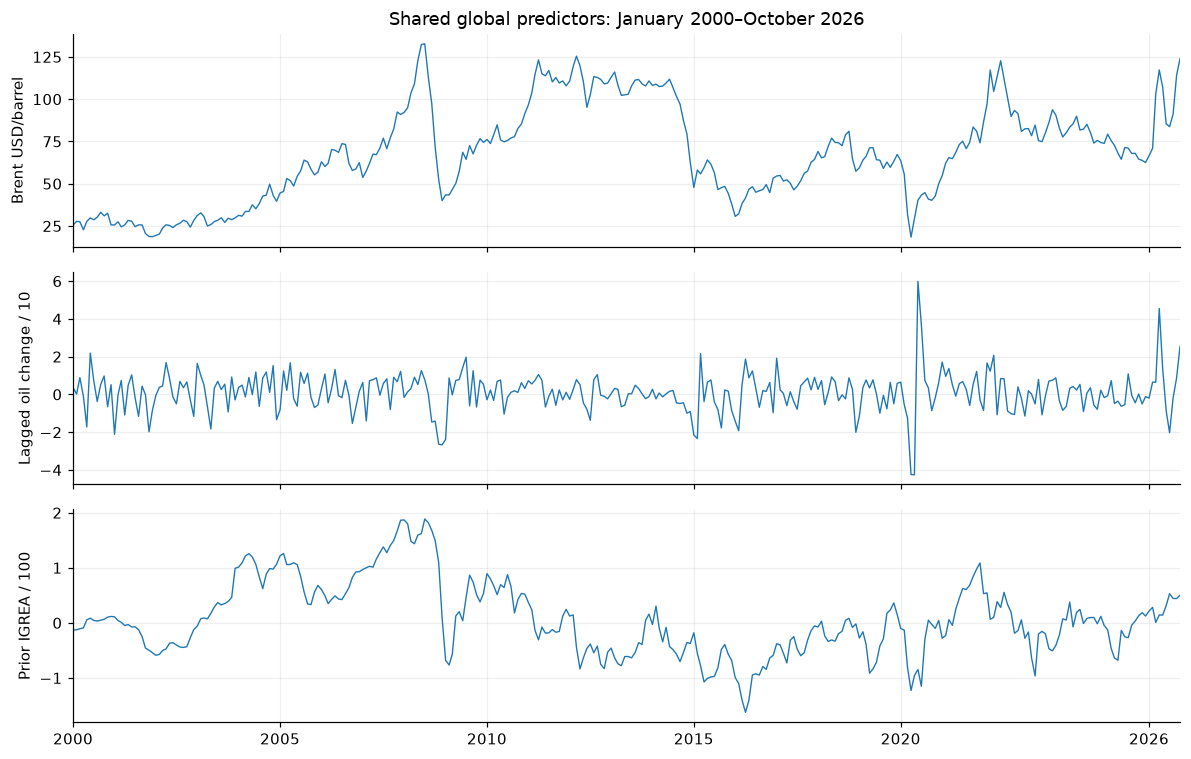

In [3]:
summary=panel.groupby('country').monthly.agg(['count','mean','median','std','min','max'])
summary.to_csv(OUT/'inflation_summary.csv');display(summary.round(4))
extremes=[]
for iso,g in groups.items():
    for event,index in [('minimum',g.monthly.idxmin()),('maximum',g.monthly.idxmax())]:
        extremes.append({'country':COUNTRIES[iso],'event':event,'date':g.loc[index,'date'],
                         'monthly_inflation':g.loc[index,'monthly'],'action':'retained'})
extremes=pd.DataFrame(extremes);extremes.to_csv(OUT/'extreme_observation_audit.csv',index=False);display(extremes)
display(groups['USA'][['oil_usd','T','C']].describe().round(4))
fig,axes=plt.subplots(3,1,figsize=(11,7),sharex=True)
for ax,col,label in zip(axes,['oil_usd','T','C'],['Brent USD/barrel','Lagged oil change / 10','Prior IGREA / 100']):
    ax.plot(groups['USA'].date,groups['USA'][col],linewidth=.9);ax.set_ylabel(label);ax.grid(alpha=.2)
full_period_axis(axes[-1]);axes[0].set_title('Shared global predictors: January 2000–October 2026')
save_figure('global_predictors')

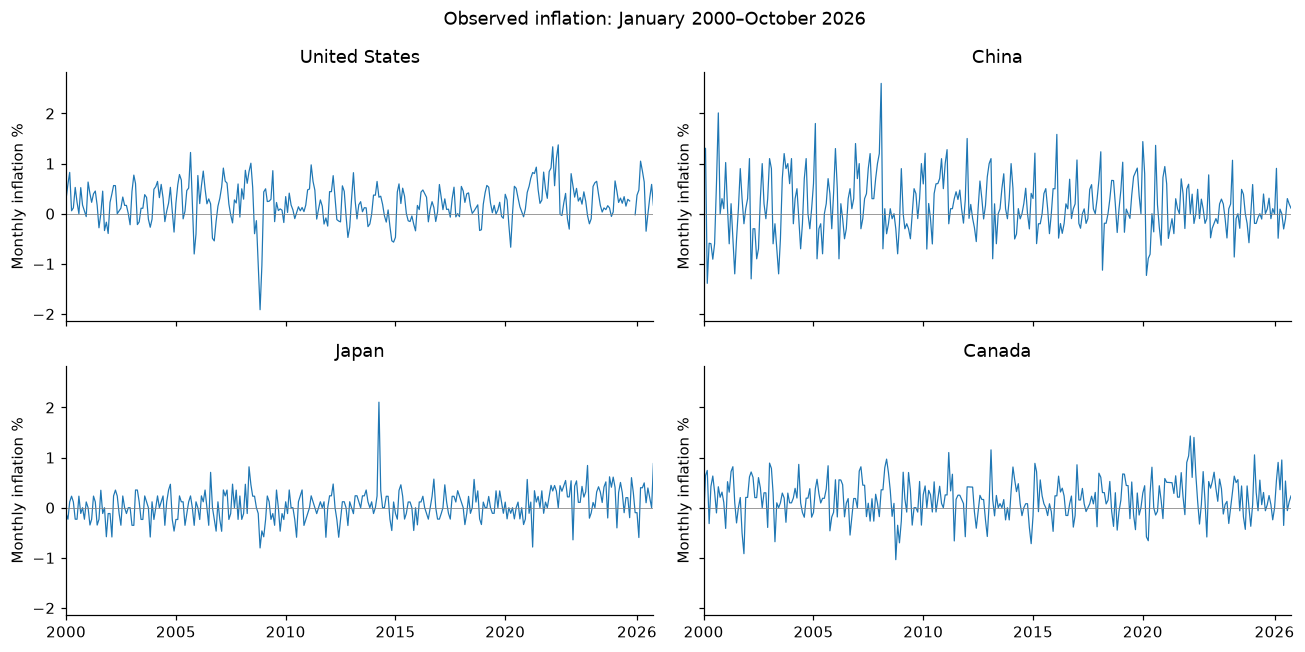

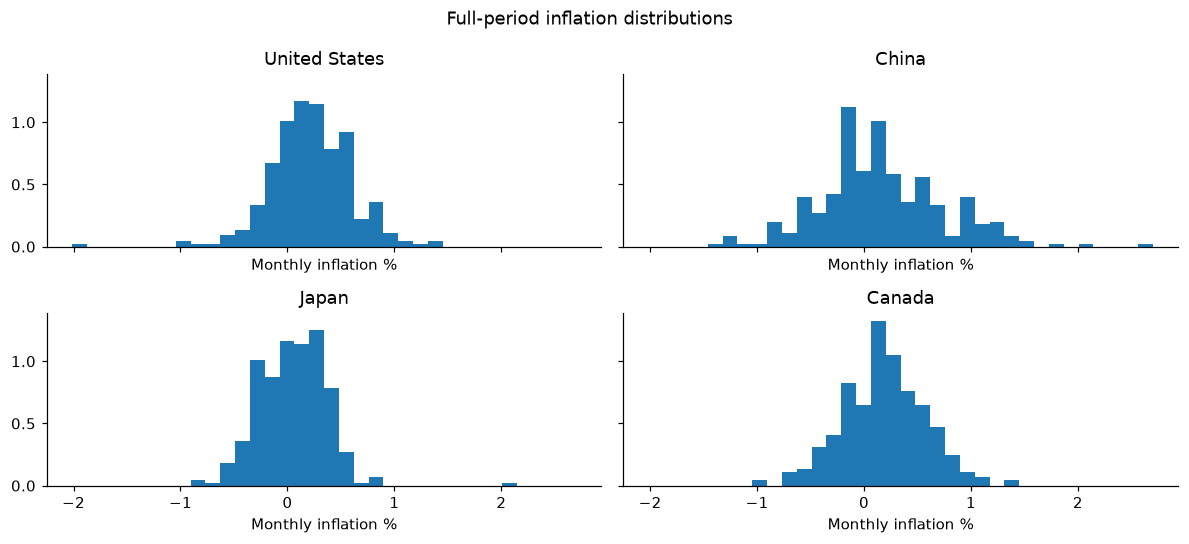

In [4]:
fig,axes=plt.subplots(2,2,figsize=(12,6),sharex=True,sharey=True)
for ax,(iso,g) in zip(axes.flat,groups.items()):
    ax.plot(g.date,g.monthly,linewidth=.8);ax.axhline(0,color='grey',linewidth=.5)
    ax.set_title(COUNTRIES[iso]);ax.set_ylabel('Monthly inflation %');full_period_axis(ax)
fig.suptitle('Observed inflation: January 2000–October 2026');save_figure('inflation_histories')
fig,axes=plt.subplots(2,2,figsize=(11,5),sharex=True,sharey=True)
bins=np.linspace(panel.monthly.min()-.1,panel.monthly.max()+.1,35)
for ax,(iso,g) in zip(axes.flat,groups.items()):
    ax.hist(g.monthly.dropna(),bins=bins,density=True);ax.set_title(COUNTRIES[iso]);ax.set_xlabel('Monthly inflation %')
fig.suptitle('Full-period inflation distributions');save_figure('inflation_distributions')

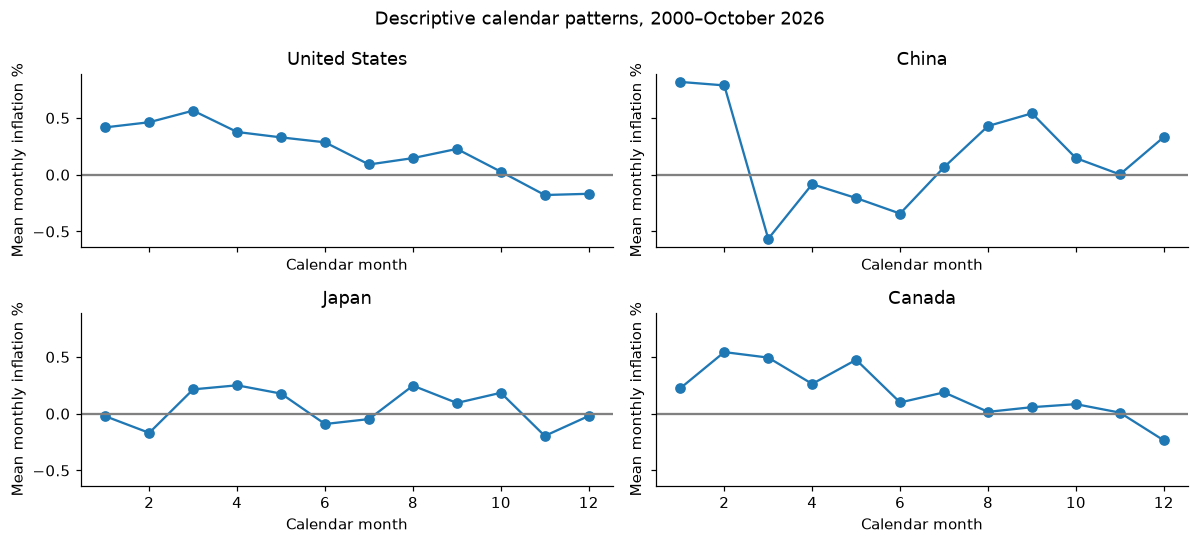

These full-period calendar summaries are descriptive; forecast seasonality is estimated using training data only.


In [5]:
seasonal=panel.groupby(['iso3','month']).monthly.agg(['mean','std','count']).reset_index()
seasonal.to_csv(OUT/'descriptive_month_patterns.csv',index=False)
fig,axes=plt.subplots(2,2,figsize=(11,5),sharex=True,sharey=True)
for ax,(iso,g) in zip(axes.flat,groups.items()):
    q=seasonal[seasonal.iso3.eq(iso)];ax.plot(q.month,q['mean'],'o-');ax.axhline(0,color='grey')
    ax.set_title(COUNTRIES[iso]);ax.set_xlabel('Calendar month');ax.set_ylabel('Mean monthly inflation %')
fig.suptitle('Descriptive calendar patterns, 2000–October 2026');save_figure('calendar_patterns')
print('These full-period calendar summaries are descriptive; forecast seasonality is estimated using training data only.')

## 4. Causal hypothesis and assumptions
Our three substantive constructs form $C\rightarrow T$, $C\rightarrow Y$, $T\rightarrow Y$.
Global demand may raise oil prices and inflation. Earlier measurement of C avoids an obvious
post-treatment adjustment, but does not establish exogeneity or sufficient confounding control.
Consistency, overlap, no remaining relevant confounding, and an adequate temporal specification are
needed for a causal interpretation. Exchange rates, expectations, taxes, subsidies, supply constraints
and policy feedback remain possible violations. Shared histories prevent treating countries as
independent exposures or ranking their causal effects from separate intervals.

Month contrasts and AR errors are statistical structure, not extra proven confounder adjustment.
Their role must be justified under the course's three-variable scope.
[Presno and Prestipino (2024)](https://www.federalreserve.gov/econres/notes/feds-notes/oil-price-shocks-and-inflation-in-a-dsge-model-of-the-global-economy-20240802.html)
motivate energy-cost transmission, but their structural supply shock and horizon differ from our
observational nominal-price estimand. We do not classify price movements as identified supply shocks.

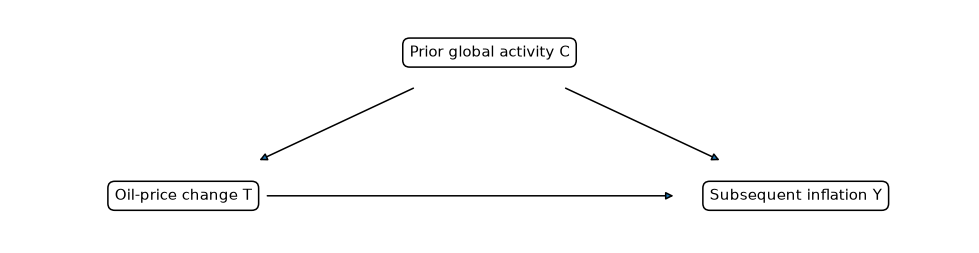

In [6]:
fig,ax=plt.subplots(figsize=(9,2.4));ax.axis('off')
positions={'C':(.5,.82),'T':(.18,.2),'Y':(.82,.2)}
for a,b in [('C','T'),('C','Y'),('T','Y')]:
    ax.annotate('',xy=positions[b],xytext=positions[a],xycoords='axes fraction',
        arrowprops={'arrowstyle':'-|>','shrinkA':55,'shrinkB':80 if a=='T' else 55})
for k,label in [('C','Prior global activity C'),('T','Oil-price change T'),('Y','Subsequent inflation Y')]:
    ax.text(*positions[k],label,ha='center',va='center',transform=ax.transAxes,
            bbox={'boxstyle':'round,pad=.45','fc':'white','ec':'black'})
save_figure('causal_dag')

## 5. Statistical model, missing outcomes and priors
Separately for each country,
$$Y_{it}=\alpha_i+\beta_iT_t+\gamma_iC_t+s_{i,m(t)}+u_{it},\qquad
u_{it}=\phi_i u_{i,t-1}+\epsilon_{it}.$$
Innovations are Gaussian $N(0,\sigma_i^2)$ or Student-$t_5(0,\sigma_i)$; sigma is a Student-t scale,
with innovation SD $\sigma\sqrt{5/3}$. Eleven orthonormal month contrasts sum to zero.
All models **condition on the first 13 observed months**, so family/dependence comparisons share
the same initial boundary without asserting an exact stationary Student-t initial distribution.
Full-period models have 309 subsequent calendar positions per country; two US outcomes are latent.

Priors: $\alpha,\gamma,\delta_k\sim N(0,0.5^2)$; $\beta\sim N(0,0.3^2)$;
$\sigma\sim\operatorname{HalfNormal}(0.5)$; $\phi\sim U(-1,1)$, independently.
For scale context, the [Fed's 2% PCE objective](https://www.federalreserve.gov/faqs/economy_14400.htm)
is approximately 0.165% monthly growth; it is neither a CPI target nor a target for every country.
The beta prior allows roughly ±0.59 inflation percentage points per 10-point oil movement.
These broad working judgments permit deflation and large departures; prior prediction and sensitivity
assess their implications. Equal sigma priors across families do not imply equal variance priors.

**Missing-state likelihood:** let M denote the two undefined US monthly outcomes and O the observed
ones after the conditioning prefix. The target uses
$$p(\theta\mid Y_O,X,Y_{0:12})\propto p(\theta)
\int \prod_{t=13}^{n-1}p(Y_t\mid Y_{t-1:t-p},X,\theta)\,dY_M.$$
Student-t errors use a Normal/Gamma mixture. Conditional on mixture weights and parameters, missing
outcomes have an exact multivariate Gaussian Gibbs update. Thus later observations inform fitting
across the gap; we do not join nonadjacent months or discard all later US observations.
Raw NaNs stay unchanged. We model observed monthly growth, without additionally imposing the known
two-month CPI-level ratio as a nonlinear constraint. This leaves some index-level information unused.

Sensitivities use AR2 in stable partial-autocorrelation coordinates and
$(1-\phi B)(1-\Phi B^{12})u_t=\epsilon_t$ for seasonal AR, plus nu=3/10 under AR1.
Forecast scoring requires observed outcomes at the model's actual lag positions; latent test outcomes
are never supplied as observations. Computation uses four seeded chains, warmup-only adaptation,
R-hat <1.01 and bulk/tail ESS >400 for every parameter **and latent outcome**, with longer retries if needed.

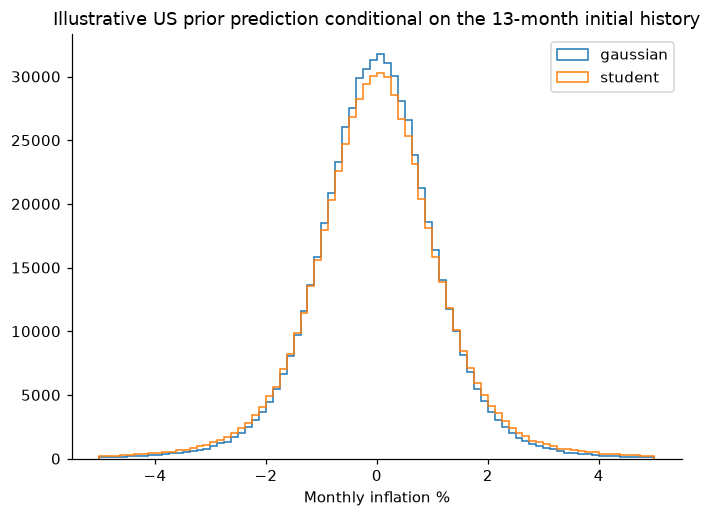

,family,lower95,median,upper95,fraction_abs_above5
0,gaussian,-2.3074,0.0091,2.2915,0.0045
1,student,-2.6262,0.0108,2.6508,0.0094


Displayed bins stop at ±5; the table reports tail mass. Only the conditioning prefix supplies outcomes here.


In [7]:
X,names,scales=specification(groups['USA']);count=2000
b=RNG.normal(size=(count,len(names)))*scales
sigma=np.abs(RNG.normal(0,.5,count));phi=RNG.uniform(-1,1,count)
prior_rows=[]
for family in ['gaussian','student']:
    mu=b@X.T;residual=np.empty_like(mu)
    residual[:,:13]=groups['USA'].monthly.to_numpy()[:13]-mu[:,:13]
    noise=RNG.standard_t(5,(count,len(X)-13)) if family=='student' else RNG.normal(size=(count,len(X)-13))
    for j in range(13,len(X)):residual[:,j]=phi*residual[:,j-1]+sigma*noise[:,j-13]
    yrep=(mu+residual)[:,13:];lo,mid,hi=np.quantile(yrep,[.025,.5,.975])
    prior_rows.append({'family':family,'lower95':lo,'median':mid,'upper95':hi,'fraction_abs_above5':np.mean(np.abs(yrep)>5)})
    plt.hist(yrep.ravel(),bins=np.linspace(-5,5,81),histtype='step',label=family)
plt.title('Illustrative US prior prediction conditional on the 13-month initial history');plt.xlabel('Monthly inflation %');plt.legend()
save_figure('prior_predictive');display(pd.DataFrame(prior_rows).round(4))
pd.DataFrame(prior_rows).to_csv(OUT/'prior_predictive_summary.csv',index=False)
print('Displayed bins stop at ±5; the table reports tail mass. Only the conditioning prefix supplies outcomes here.')

## 6. Synthetic validation, separate from real observations
True beta=.15, gamma=.25, scale=.15 and AR1 persistence=.4. We fit separately generated Gaussian
and Student-t datasets with/without demand. The known simulation is not merged with measured data.
Independent tests verify the missing-state Gaussian conditional against an analytic covariance model
and verify the new Student-t kernel matches the established kernel on a complete calendar.
Forty additional independent synthetic datasets cross weak/strong confounding and low/high persistence;
their existing results use the same complete-calendar conditional Student-t AR1 likelihood.

SIM/gaussian/adjusted=False pass; attempt 1


SIM/gaussian/adjusted=True pass; attempt 1


SIM/student/adjusted=False pass; attempt 1


SIM/student/adjusted=True pass; attempt 1


,family,adjusted,truth,beta,lower95,upper95
0,gaussian,False,0.15,0.2066,0.1804,0.2335
1,gaussian,True,0.15,0.1551,0.1329,0.1775
2,student,False,0.15,0.2150,0.1841,0.2456
3,student,True,0.15,0.1543,0.1257,0.1825


,family,parameter,truth,mean,lower95,upper95,covered
1,gaussian,beta,0.15,0.1551,0.1329,0.1775,True
2,gaussian,gamma,0.25,0.2317,0.1931,0.2702,True
14,gaussian,sigma,0.15,0.1520,0.1397,0.1656,True
15,gaussian,kappa1,0.40,0.4255,0.3110,0.5351,True
17,student,beta,0.15,0.1543,0.1257,0.1825,True
18,student,gamma,0.25,0.2527,0.2063,0.2978,True
30,student,sigma,0.15,0.1616,0.1454,0.1798,True
31,student,kappa1,0.40,0.3469,0.2430,0.4460,True


,confounding,persistence,adjusted,replications,bias,estimation_RMSE,interval_coverage,coverage_MC_lower95,coverage_MC_upper95
0,0.1,0.2,False,10,0.0063,0.0193,1.0,0.7225,1.0000
1,0.1,0.2,True,10,-0.0010,0.0137,1.0,0.7225,1.0000
2,0.1,0.7,False,10,0.0045,0.0158,1.0,0.7225,1.0000
3,0.1,0.7,True,10,-0.0066,0.0143,0.9,0.5958,0.9821
4,0.8,0.2,False,10,0.0825,0.0837,0.0,0.0000,0.2775
5,0.8,0.2,True,10,0.0010,0.0123,0.9,0.5958,0.9821
6,0.8,0.7,False,10,0.0592,0.0612,0.1,0.0179,0.4042
7,0.8,0.7,True,10,-0.0030,0.0155,0.9,0.5958,0.9821


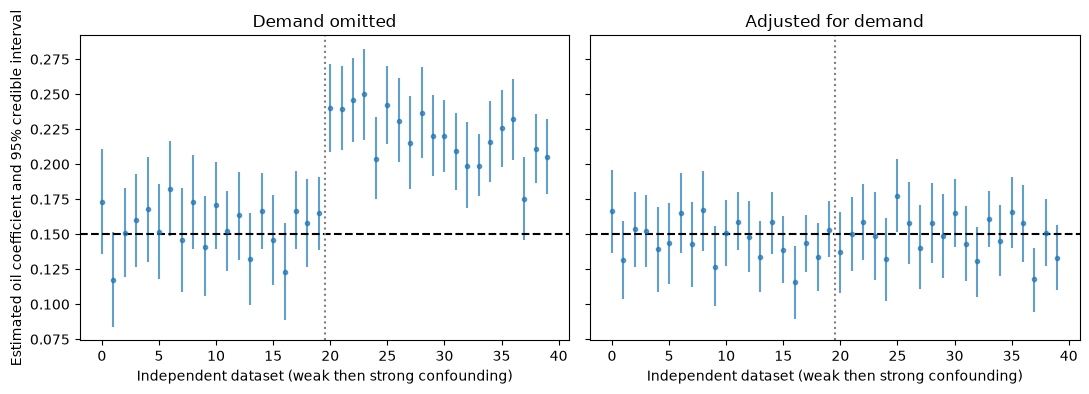

Ten replications per scenario give imprecise coverage; Wilson Monte Carlo intervals are reported.


In [8]:
simulation=[];parameter_recovery=[]
for family in ['gaussian','student']:
    synthetic,truth=simulation_data(family)
    for adjusted in [False,True]:
        fit=fit_combined(synthetic,family=family,adjusted=adjusted,label=f'SIM/{family}/adjusted={adjusted}')
        q=fit['diagnostics'].query("parameter == 'beta'").iloc[0]
        simulation.append({'family':family,'adjusted':adjusted,'truth':.15,'beta':q['mean'],'lower95':q.lower95,'upper95':q.upper95})
        if adjusted:
            table=fit['diagnostics'].copy();table['truth']=truth;table['family']=family
            table['covered']=(table.truth>=table.lower95)&(table.truth<=table.upper95)
            parameter_recovery.append(table)
display(pd.DataFrame(simulation).round(4))
recovery=pd.concat(parameter_recovery,ignore_index=True)
recovery.to_csv(OUT/'synthetic_parameter_recovery.csv',index=False)
display(recovery[recovery.parameter.isin(['beta','gamma','sigma','kappa1'])][['family','parameter','truth','mean','lower95','upper95','covered']].round(4))
stress=pd.read_csv(ROOT/'results/strengthening/simulation_summary.csv')
display(stress.round(4))
display(Image(filename=str(ROOT/'results/strengthening/simulation_recovery.png')))
print('Ten replications per scenario give imprecise coverage; Wilson Monte Carlo intervals are reported.')

## 7. Main model fitting — January 2000–October 2026
**This cell trains the main real-data models.** Each call fits one country, family and adjustment
combination using the entire combined calendar. Unchanged code/data/settings reuse a recorded local
posterior cache. Latent US monthly outcomes are sampled internally; they remain missing in the dataset.

USA/full/gaussian/adjusted=False pass; attempt 1


USA/full/gaussian/adjusted=True pass; attempt 1


USA/full/student/adjusted=False pass; attempt 1


USA/full/student/adjusted=True pass; attempt 1


CHN/full/gaussian/adjusted=False pass; attempt 1


CHN/full/gaussian/adjusted=True pass; attempt 1


... (12 outputs left out)

CAN/full/student/adjusted=True pass; attempt 1


C:\Users\Omkar\AppData\Local\Temp\ipykernel_12508\328604546.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(estimates.round(4))


,iso3,family,adjusted,beta,lower95,upper95,observed_after_prefix,latent_outcomes,last_month
0,USA,gaussian,False,0.0982,0.0629,0.1343,307,2,2026-10-01
1,USA,gaussian,True,0.0998,0.0646,0.1347,307,2,2026-10-01
2,USA,student,False,0.0873,0.0561,0.1211,307,2,2026-10-01
3,USA,student,True,0.0902,0.0596,0.1251,307,2,2026-10-01
4,CHN,gaussian,False,0.0871,0.0426,0.1324,309,0,2026-10-01
5,CHN,gaussian,True,0.0837,0.0376,0.1287,309,0,2026-10-01
6,CHN,student,False,0.0937,0.0531,0.1353,309,0,2026-10-01
7,CHN,student,True,0.0915,0.0511,0.1337,309,0,2026-10-01
8,JPN,gaussian,False,0.0378,0.0074,0.0680,309,0,2026-10-01
9,JPN,gaussian,True,0.0372,0.0066,0.0682,309,0,2026-10-01


max_Rhat  min_bulk_ESS  min_tail_ESS
iso3 family   adjusted                                      
CAN  gaussian False     1.000836   1987.062235   2245.486110
              True      1.004850   1763.009928   2219.951922
     student  False     1.001987   1334.030491   1599.260157
              True      1.003382   1207.266812   1936.515783
CHN  gaussian False     1.001724   2026.828088   2103.045993
              True      1.001735   2231.240428   2395.611434
     student  False     1.003109   1346.101795   1912.676363
              True      1.003773   1266.553677   1926.748610
JPN  gaussian False     1.001909   1907.376315   2412.770244
              True      1.003920   2206.875785   2465.288341
     student  False     1.005883   1215.170850   1515.671154
              True      1.003862   1433.515983   2048.651942
USA  gaussian False     1.002520   1258.061807   1971.968479
              True      1.002565   1436.888897   2105.411440
     student  False     1.006812    752.485687   1594.638861
              True      1.003842    786.156035   1474.708365

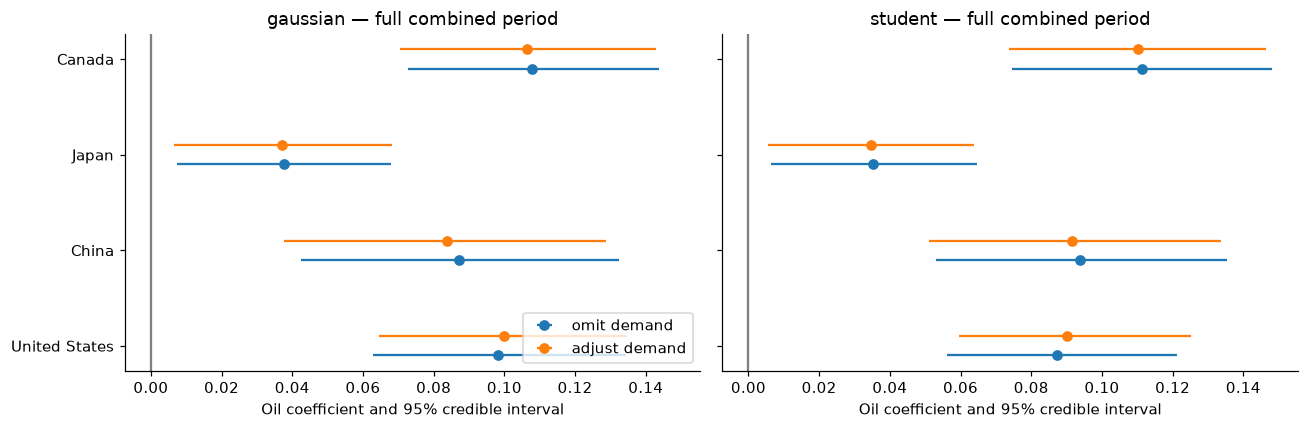

In [9]:
fits={};estimate_rows=[];diagnostic_tables=[]
for iso,g in groups.items():
    for family in ['gaussian','student']:
        for adjusted in [False,True]:
            fit=fit_combined(g,family=family,adjusted=adjusted,label=f'{iso}/full/{family}/adjusted={adjusted}')
            fits[(iso,family,adjusted)]=fit
            q=fit['diagnostics'].query("parameter == 'beta'").iloc[0]
            estimate_rows.append({'iso3':iso,'family':family,'adjusted':adjusted,'beta':q['mean'],
                'lower95':q.lower95,'upper95':q.upper95,'observed_after_prefix':fit['n_observed'],
                'latent_outcomes':len(fit['missing']),'last_month':END})
            d=fit['diagnostics'].copy();d['iso3']=iso;d['family']=family;d['adjusted']=adjusted;diagnostic_tables.append(d)
estimates=pd.DataFrame(estimate_rows);diagnostics=pd.concat(diagnostic_tables,ignore_index=True)
estimates.to_csv(OUT/'country_estimates.csv',index=False);diagnostics.to_csv(OUT/'main_sampling_diagnostics.csv',index=False)
assert diagnostics.sampling_pass.all()
display(estimates.round(4))
display(diagnostics.groupby(['iso3','family','adjusted']).agg(max_Rhat=('r_hat','max'),min_bulk_ESS=('ess_bulk','min'),min_tail_ESS=('ess_tail','min')))
fig,axes=plt.subplots(1,2,figsize=(12,4),sharex=True,sharey=True)
for ax,family in zip(axes,['gaussian','student']):
    for offset,adjusted in [(-.1,False),(.1,True)]:
        q=estimates[estimates.family.eq(family)&estimates.adjusted.eq(adjusted)].set_index('iso3').loc[list(COUNTRIES)]
        ax.errorbar(q.beta,np.arange(4)+offset,xerr=[q.beta-q.lower95,q.upper95-q.beta],fmt='o',label='adjust demand' if adjusted else 'omit demand')
    ax.axvline(0,color='grey');ax.set_title(family+' — full combined period');ax.set_xlabel('Oil coefficient and 95% credible interval')
axes[0].set_yticks(range(4),list(COUNTRIES.values()));axes[0].legend();save_figure('country_coefficients')

## 8. Posterior evaluation, forecasting and robustness
The following suite recomputes every real-data sensitivity on the combined calendar. Rolling training
cutoffs are December 2009, 2014 and 2019; disjoint evaluation windows end December 2014, December
2019 and **October 2026**. Forecasts condition on available lagged actual residuals without refitting
coefficients on test outcomes. A separate pre-2025 training sample evaluates recent events.
These are retrospective revised-data predictions, not real-time forecasts or an untouched confirmatory test.

USA/full/ar1/gaussian/nu=NA/adjusted=False pass; attempt 1


USA/full/ar1/gaussian/nu=NA/adjusted=True pass; attempt 1


USA/full/ar1/student/nu=5/adjusted=False pass; attempt 1


USA/full/ar1/student/nu=5/adjusted=True pass; attempt 1


USA/full/ar2/student/nu=5/adjusted=True pass; attempt 1


USA/full/sar12/student/nu=5/adjusted=True pass; attempt 1


... (128 outputs left out)

CAN/recent-training/through2024/oil=True pass; attempt 1


C:\Users\Omkar\AppData\Local\Temp\ipykernel_12508\3291883563.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(checks.round(4));display(predictive.round(4))


,iso3,kind,family,nu,diagnostic_run_n,LB_p12,LB_p24,calendar_ACF1,calendar_ACF12,calendar_ACF24,diagnostic_first_date,diagnostic_last_date
0,USA,ar1,gaussian,NaN,296,0.0517,0.0513,0.0137,-0.0772,-0.0500,2001-02-01,2025-09-01
1,USA,ar1,student,5.0,296,0.0201,0.0248,0.1046,-0.0495,-0.0275,2001-02-01,2025-09-01
2,USA,ar2,student,5.0,296,0.0075,0.0100,0.1043,-0.0450,-0.0212,2001-02-01,2025-09-01
3,USA,sar12,student,5.0,296,0.0132,0.0206,0.1026,-0.0093,-0.0329,2001-02-01,2025-09-01
4,USA,ar1,student,3.0,296,0.0177,0.0229,0.1186,-0.0421,-0.0214,2001-02-01,2025-09-01
5,USA,ar1,student,10.0,296,0.0281,0.0322,0.0810,-0.0589,-0.0354,2001-02-01,2025-09-01
6,CHN,ar1,gaussian,NaN,309,0.0079,0.0041,-0.0070,-0.0975,0.0506,2001-02-01,2026-10-01
7,CHN,ar1,student,5.0,309,0.0063,0.0029,-0.0222,-0.1055,0.0478,2001-02-01,2026-10-01
8,CHN,ar2,student,5.0,309,0.0115,0.0055,-0.0122,-0.1042,0.0497,2001-02-01,2026-10-01
9,CHN,sar12,student,5.0,309,0.0181,0.0086,-0.0224,-0.0206,0.0642,2001-02-01,2026-10-01


,iso3,kind,family,nu,statistic,observed,lower95,upper95,outside95
0,USA,ar1,gaussian,NaN,minimum,-1.9153,-1.1644,-0.6083,True
1,USA,ar1,gaussian,NaN,maximum,1.3736,1.0181,1.5424,False
2,USA,ar1,gaussian,NaN,sd,0.3830,0.3383,0.4186,False
3,USA,ar1,student,5.0,minimum,-1.9153,-1.8877,-0.6040,True
4,USA,ar1,student,5.0,maximum,1.3736,1.0011,2.3520,False
...,...,...,...,...,...,...,...,...,...
67,CAN,ar1,student,3.0,maximum,1.4305,1.2395,5.4844,False
68,CAN,ar1,student,3.0,sd,0.3880,0.3791,0.5861,False
69,CAN,ar1,student,10.0,minimum,-1.0372,-1.5221,-0.7214,False
70,CAN,ar1,student,10.0,maximum,1.4305,1.0629,1.9425,False


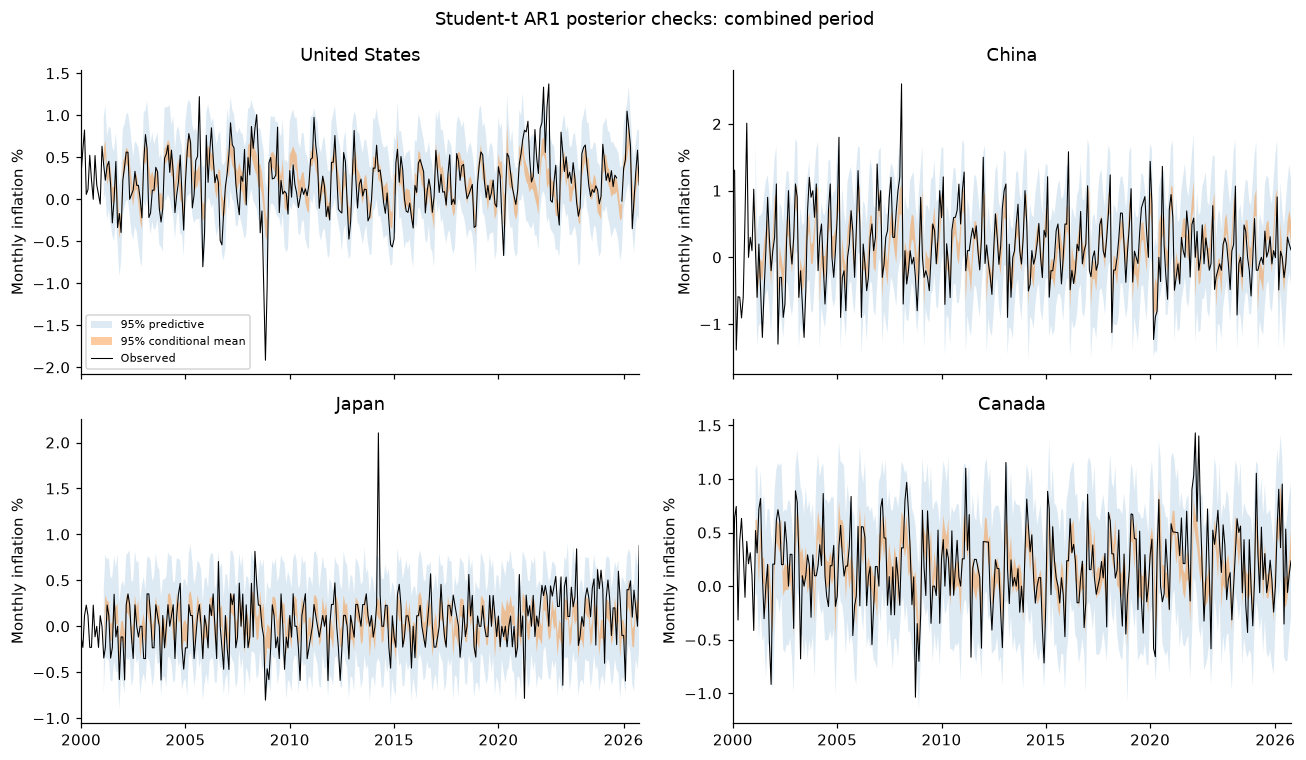

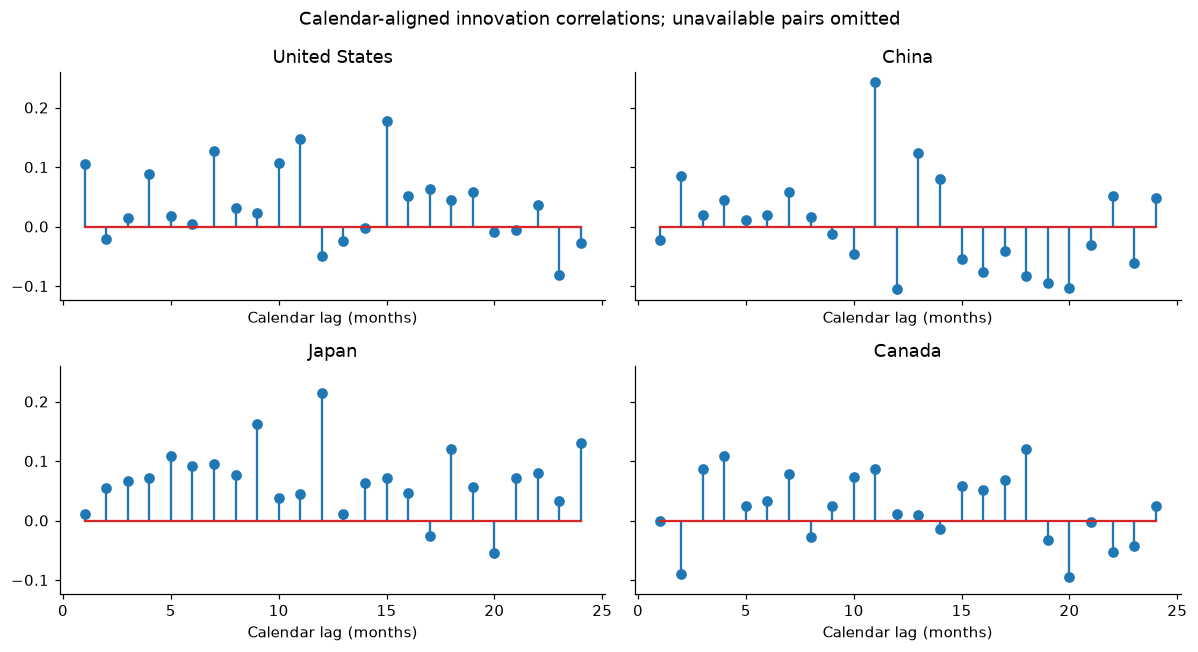

,USA,CHN,JPN,CAN
USA,1.000,0.107,0.173,0.613
CHN,0.107,1.000,0.070,0.089
JPN,0.173,0.070,1.000,0.160
CAN,0.613,0.089,0.160,1.000


Ljung–Box statistics use the **longest contiguous observed innovation run**, whose dates and size are shown above. We never compress the US gap into adjacent months. These approximate diagnostics do not certify adequacy.

In [10]:
analysis=run_combined()
checks=analysis['innovation_checks'];predictive=analysis['predictive_checks']
display(checks.round(4));display(predictive.round(4))
fig,axes=plt.subplots(2,2,figsize=(12,7),sharex=True)
for ax,(iso,g) in zip(axes.flat,groups.items()):
    mu,rep=analysis['replicated'][(iso,'student')]
    dates=g.date.iloc[13:]
    ax.fill_between(dates,*np.quantile(rep[:,13:],[.025,.975],axis=0),alpha=.15,label='95% predictive')
    ax.fill_between(dates,*np.quantile(mu[:,13:],[.025,.975],axis=0),alpha=.4,label='95% conditional mean')
    ax.plot(g.date,g.monthly,color='black',linewidth=.7,label='Observed')
    ax.set_title(COUNTRIES[iso]);full_period_axis(ax);ax.set_ylabel('Monthly inflation %')
axes[0,0].legend(fontsize=7);fig.suptitle('Student-t AR1 posterior checks: combined period');save_figure('posterior_predictive')
fig,axes=plt.subplots(2,2,figsize=(11,6),sharex=True,sharey=True)
innovation_series={}
for ax,(iso,g) in zip(axes.flat,groups.items()):
    e=innovations(fits[(iso,'student',True)]);innovation_series[iso]=e
    acf_values=[pd.Series(e).autocorr(lag=k) for k in range(1,25)]
    ax.stem(range(1,25),acf_values);ax.set_title(COUNTRIES[iso]);ax.set_xlabel('Calendar lag (months)')
fig.suptitle('Calendar-aligned innovation correlations; unavailable pairs omitted');save_figure('innovation_ACF')
display(pd.DataFrame(innovation_series).corr().round(3))
display(Markdown('Ljung–Box statistics use the **longest contiguous observed innovation run**, whose dates and size are shown above. We never compress the US gap into adjacent months. These approximate diagnostics do not certify adequacy.'))

,iso3,kind,oil,window,n_test,RMSE,MAE,log_score,coverage95
0,USA,ar1,False,2010-01--2014-12,60,0.2070,0.1574,0.0209,1.0000
1,USA,ar1,True,2010-01--2014-12,60,0.1778,0.1363,0.0966,1.0000
2,USA,ar2,False,2010-01--2014-12,60,0.2022,0.1560,0.0564,1.0000
3,USA,ar2,True,2010-01--2014-12,60,0.1838,0.1440,0.0995,1.0000
4,USA,sar12,False,2010-01--2014-12,60,0.2065,0.1552,0.0268,1.0000
...,...,...,...,...,...,...,...,...,...
67,CAN,ar1,True,2020-01--2026-10,82,0.3686,0.2782,-0.4193,0.9024
68,CAN,ar2,False,2020-01--2026-10,82,0.3663,0.2695,-0.3854,0.9146
69,CAN,ar2,True,2020-01--2026-10,82,0.3762,0.2816,-0.4282,0.9024
70,CAN,sar12,False,2020-01--2026-10,82,0.3595,0.2620,-0.3714,0.9390


,iso3,kind,n_test,RMSE,RMSE_no_oil,oil_gain_percent,oil_gain_lower95,oil_gain_upper95,mean_log_score,structure_gain_percent,structure_lower95,structure_upper95
0,USA,ar1,197,0.240,0.250,3.808,-4.740,15.450,-0.001,0.000,0.000,0.000
1,USA,ar2,197,0.245,0.251,2.420,-3.393,10.859,-0.010,-2.179,-3.829,-0.009
2,USA,sar12,197,0.242,0.253,4.145,-3.997,15.446,-0.003,-0.870,-1.843,0.284
3,CHN,ar1,202,0.394,0.394,-0.023,-3.309,3.426,-0.484,0.000,0.000,0.000
4,CHN,ar2,202,0.392,0.391,-0.213,-3.588,3.359,-0.483,0.375,-0.144,0.878
5,CHN,sar12,202,0.398,0.396,-0.312,-3.427,3.071,-0.490,-1.015,-3.126,1.159
6,JPN,ar1,202,0.324,0.320,-1.426,-3.164,0.816,-0.302,0.000,0.000,0.000
7,JPN,ar2,202,0.329,0.322,-2.184,-4.336,0.819,-0.315,-1.401,-2.801,0.534
8,JPN,sar12,202,0.311,0.310,-0.422,-2.281,2.181,-0.233,4.035,2.142,6.773
9,CAN,ar1,202,0.318,0.329,3.185,-2.572,9.038,-0.267,0.000,0.000,0.000


**Simple benchmarks and AR1 forecasts on identical eligible months within each window**

,iso3,window,model,n_test,RMSE,MAE
0,USA,2010-01--2014-12,last month,60,0.3082,0.2483
1,USA,2010-01--2014-12,same month last year,60,0.3164,0.2541
2,USA,2010-01--2014-12,training mean,60,0.3278,0.2657
3,USA,2010-01--2014-12,training month mean,60,0.2362,0.1894
4,USA,2010-01--2014-12,AR1 without oil,60,0.2070,0.1574
...,...,...,...,...,...,...
67,CAN,2020-01--2026-10,same month last year,82,0.4753,0.3620
68,CAN,2020-01--2026-10,training mean,82,0.4332,0.3434
69,CAN,2020-01--2026-10,training month mean,82,0.3690,0.2726
70,CAN,2020-01--2026-10,AR1 without oil,82,0.3605,0.2632


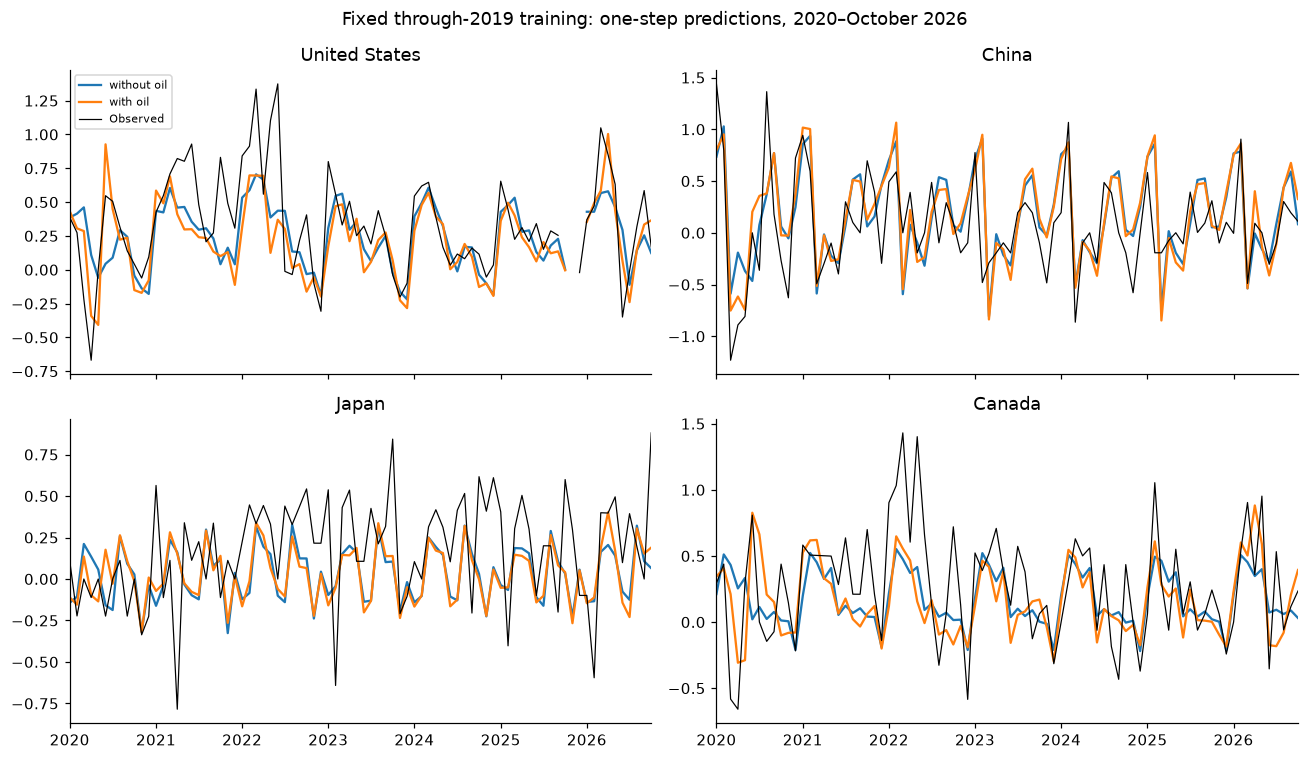

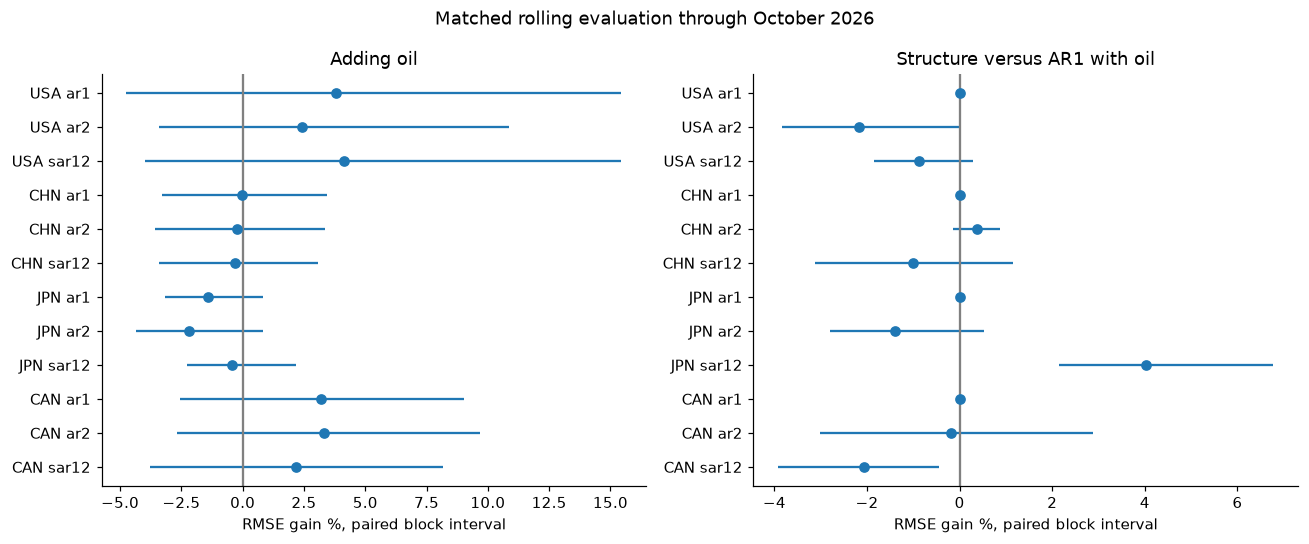

Structure and oil comparisons use the same eligible calendar months across all six models within each country/window. Intervals resample paired circular 12-month blocks within windows, 2,000 replicates. All points are conditional on fitted forecasts; inspected model rankings remain exploratory.

In [11]:
forecast=analysis['rolling_predictions'];aggregate=analysis['rolling_aggregate']
display(analysis['rolling_metrics'].round(4));display(aggregate.round(3))
display(Markdown('**Simple benchmarks and AR1 forecasts on identical eligible months within each window**'))
display(analysis['benchmark_metrics'].round(4))
last_window=forecast.window.iloc[-1]
fig,axes=plt.subplots(2,2,figsize=(12,7),sharex=True)
for ax,iso in zip(axes.flat,COUNTRIES):
    for oil in [False,True]:
        q=forecast[forecast.iso3.eq(iso)&forecast.kind.eq('ar1')&forecast.oil.eq(oil)&forecast.window.eq(last_window)]
        ax.plot(q.date,q.prediction,label='with oil' if oil else 'without oil')
    ax.plot(q.date,q.actual,color='black',linewidth=.8,label='Observed');ax.set_title(COUNTRIES[iso]);ax.set_xlim(q.date.min(),END)
axes[0,0].legend(fontsize=7);fig.suptitle('Fixed through-2019 training: one-step predictions, 2020–October 2026');save_figure('holdout_predictions')
fig,axes=plt.subplots(1,2,figsize=(12,5))
labels=[r.iso3+' '+r.kind for r in aggregate.itertuples()];positions=np.arange(len(labels))
for ax,center,low,high,title in [(axes[0],'oil_gain_percent','oil_gain_lower95','oil_gain_upper95','Adding oil'),
    (axes[1],'structure_gain_percent','structure_lower95','structure_upper95','Structure versus AR1 with oil')]:
    ax.errorbar(aggregate[center],positions,xerr=[aggregate[center]-aggregate[low],aggregate[high]-aggregate[center]],fmt='o')
    ax.axvline(0,color='grey');ax.set_yticks(positions,labels);ax.invert_yaxis();ax.set_title(title);ax.set_xlabel('RMSE gain %, paired block interval')
fig.suptitle('Matched rolling evaluation through October 2026');save_figure('rolling_gains')
display(Markdown('Structure and oil comparisons use the same eligible calendar months across all six models within each country/window. Intervals resample paired circular 12-month blocks within windows, 2,000 replicates. All points are conditional on fitted forecasts; inspected model rankings remain exploratory.'))

,iso3,oil,n_test,RMSE,MAE,log_score,coverage95
0,USA,False,19,0.2476,0.1773,0.0186,0.9474
1,USA,True,19,0.2172,0.1683,0.1020,0.9474
2,CHN,False,22,0.3471,0.2585,-0.3584,0.9545
3,CHN,True,22,0.3647,0.2696,-0.3890,0.9545
4,JPN,False,22,0.3246,0.2695,-0.3915,0.9091
5,JPN,True,22,0.3230,0.2667,-0.4046,0.8636
6,CAN,False,22,0.2746,0.2073,-0.1522,1.0000
7,CAN,True,22,0.2734,0.2089,-0.1381,1.0000


,iso3,n_test,RMSE_gain_percent,block3_lower95,block3_upper95,block6_lower95,block6_upper95
0,USA,19,12.281,-6.033,21.013,-6.893,18.265
1,CHN,22,-5.086,-15.187,4.594,-11.652,4.736
2,JPN,22,0.500,-7.123,5.939,-4.300,4.009
3,CAN,22,0.448,-19.696,13.787,-13.997,14.478


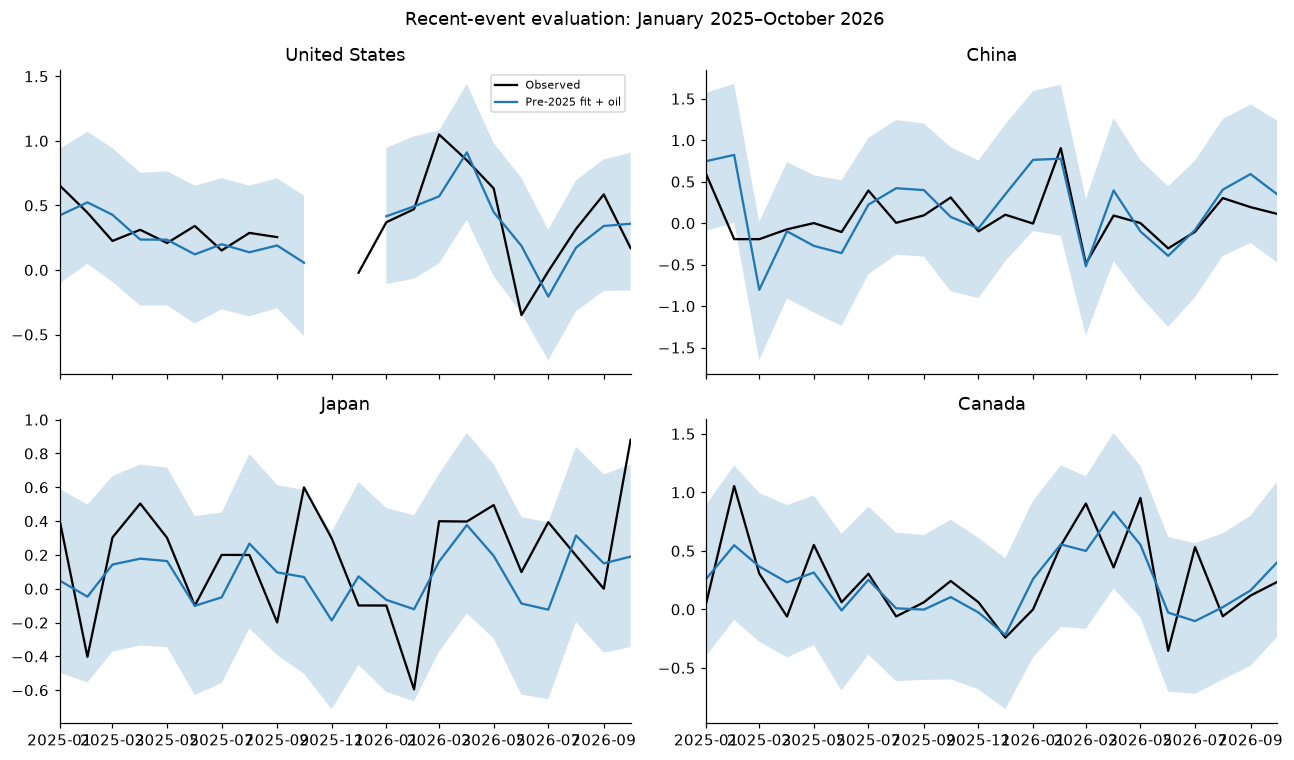

,iso3,beta_through2024,lower95_through2024,upper95_through2024,beta_combined,lower95_combined,upper95_combined
0,USA,0.0913,0.0570,0.1279,0.0902,0.0596,0.1251
1,CHN,0.1032,0.0589,0.1481,0.0915,0.0511,0.1337
2,JPN,0.0372,0.0078,0.0669,0.0346,0.0056,0.0637
3,CAN,0.1160,0.0765,0.1539,0.1101,0.0737,0.1463


The table above is the **historical reference comparison only**. Main estimates and charts use the combined period. October oil predicts November inflation under our lag-one question; that outcome is not yet observed.

In [12]:
recent=analysis['recent_predictions'];display(analysis['recent_metrics'].round(4));display(analysis['recent_gains'].round(3))
fig,axes=plt.subplots(2,2,figsize=(12,7),sharex=True)
for ax,iso in zip(axes.flat,COUNTRIES):
    q=recent[recent.iso3.eq(iso)&recent.oil]
    ax.plot(q.date,q.actual,color='black',label='Observed');ax.plot(q.date,q.prediction,label='Pre-2025 fit + oil')
    ax.fill_between(q.date,q.lower95,q.upper95,alpha=.2);ax.set_title(COUNTRIES[iso]);ax.set_xlim(q.date.min(),END)
axes[0,0].legend(fontsize=7);fig.suptitle('Recent-event evaluation: January 2025–October 2026');save_figure('recent_forecasts')
reference=analysis['historical_reference'];current=estimates[estimates.family.eq('student')&estimates.adjusted]
display(reference.merge(current,on='iso3',suffixes=('_through2024','_combined'))[
    ['iso3','beta_through2024','lower95_through2024','upper95_through2024','beta_combined','lower95_combined','upper95_combined']].round(4))
display(Markdown('The table above is the **historical reference comparison only**. Main estimates and charts use the combined period. October oil predicts November inflation under our lag-one question; that outcome is not yet observed.'))

In [13]:
sensitivity=analysis['coefficients'];display(sensitivity[sensitivity.experiment.ne('full')].round(4))
full_sensitivity=sensitivity[sensitivity.experiment.eq('full')]
display(full_sensitivity[full_sensitivity.variant.str.contains('student')].round(4))
prior=[]
for iso in COUNTRIES:
    f=fits[(iso,'student',True)];flat=f['chains'].reshape(-1,len(f['names']));p=f['p']
    for label,lw in [('beta SD .15',-.5*(flat[:,1]/.15)**2+.5*(flat[:,1]/.3)**2),
                     ('beta SD .60',-.5*(flat[:,1]/.6)**2+.5*(flat[:,1]/.3)**2),
                     ('phi transformed Beta(2,2)',np.log1p(-flat[:,p+1]**2))]:
        w=np.exp(lw-lw.max());w/=w.sum();order=np.argsort(flat[:,1])
        lo,hi=np.interp([.025,.975],np.cumsum(w[order]),flat[order,1])
        prior.append({'iso3':iso,'prior':label,'beta':w@flat[:,1],'lower95':lo,'upper95':hi,'weight_ESS':1/(w@w)})
prior=pd.DataFrame(prior);prior.to_csv(OUT/'prior_sensitivity.csv',index=False);display(prior.round(4))
display(Markdown('Prior-weight ESS measures weight concentration, not chain mixing. Alternative single-lag fits change treatment timing; they do not estimate a cumulative response. Pre/post-2020 fits have different precision and do not form a formal causal regime test. Fixed nu=3/5/10 changes variance as well as tail shape under a common scale prior.'))

,iso3,experiment,variant,beta,lower95,upper95,n_observed
32,USA,oil_lag,lag/2,-0.0087,-0.0410,0.0226,307
33,USA,oil_lag,lag/3,-0.0236,-0.0526,0.0050,307
34,USA,period,pre2020,0.1326,0.0850,0.1810,227
35,USA,period,2020-onward,0.0671,0.0140,0.1233,80
36,CHN,oil_lag,lag/2,0.0013,-0.0484,0.0520,309
37,CHN,oil_lag,lag/3,0.0099,-0.0382,0.0588,309
38,CHN,period,pre2020,0.1013,0.0422,0.1606,227
39,CHN,period,2020-onward,0.0902,0.0371,0.1470,82
40,JPN,oil_lag,lag/2,0.0209,-0.0063,0.0477,309
41,JPN,oil_lag,lag/3,-0.0052,-0.0316,0.0212,309


,iso3,experiment,variant,beta,lower95,upper95,n_observed
2,USA,full,full/ar1/student/nu=5/adjusted=False,0.0873,0.0561,0.1211,307
3,USA,full,full/ar1/student/nu=5/adjusted=True,0.0902,0.0596,0.1251,307
4,USA,full,full/ar2/student/nu=5/adjusted=True,0.0805,0.0454,0.1176,307
5,USA,full,full/sar12/student/nu=5/adjusted=True,0.0881,0.0571,0.1210,307
6,USA,full,full/ar1/student/nu=3/adjusted=True,0.0861,0.0553,0.1199,307
7,USA,full,full/ar1/student/nu=10/adjusted=True,0.0942,0.0609,0.1290,307
10,CHN,full,full/ar1/student/nu=5/adjusted=False,0.0937,0.0531,0.1353,309
11,CHN,full,full/ar1/student/nu=5/adjusted=True,0.0915,0.0511,0.1337,309
12,CHN,full,full/ar2/student/nu=5/adjusted=True,0.0912,0.0513,0.1315,309
13,CHN,full,full/sar12/student/nu=5/adjusted=True,0.0908,0.0505,0.1315,309


,iso3,prior,beta,lower95,upper95,weight_ESS
0,USA,beta SD .15,0.0894,0.0587,0.1239,9973.7308
1,USA,beta SD .60,0.0905,0.0597,0.1257,9998.2666
2,USA,"phi transformed Beta(2,2)",0.0905,0.0598,0.1257,9988.3646
3,CHN,beta SD .15,0.0902,0.0500,0.1318,9958.3785
4,CHN,beta SD .60,0.0919,0.0513,0.1340,9997.2223
5,CHN,"phi transformed Beta(2,2)",0.0916,0.0510,0.1337,9997.4604
6,JPN,beta SD .15,0.0343,0.0054,0.0633,9996.9318
7,JPN,beta SD .60,0.0346,0.0056,0.0638,9999.8031
8,JPN,"phi transformed Beta(2,2)",0.0346,0.0056,0.0637,9996.8483
9,CAN,beta SD .15,0.1088,0.0726,0.1450,9954.0507


Prior-weight ESS measures weight concentration, not chain mixing. Alternative single-lag fits change treatment timing; they do not estimate a cumulative response. Pre/post-2020 fits have different precision and do not form a formal causal regime test. Fixed nu=3/5/10 changes variance as well as tail shape under a common scale prior.

## 9. Findings, interpretation and limitations
The following conclusions are generated from the combined-period fits and chronological evaluation.
Sampling convergence is distinct from model adequacy, forecast usefulness and causal identification.

In [14]:
lines=['# Combined-period findings: January 2000–October 2026','',
    'Verified 1,288 calendar rows and 1,286 observed monthly inflation outcomes. Two US outcomes are integrated as latent states; raw gaps remain unchanged. All retained parameter and latent-state sampling checks pass.','',
    '## Main Student-t AR1 associations','']
for iso,name in COUNTRIES.items():
    a=estimates[estimates.iso3.eq(iso)&estimates.family.eq('student')&estimates.adjusted].iloc[0]
    b=estimates[estimates.iso3.eq(iso)&estimates.family.eq('student')&~estimates.adjusted].iloc[0]
    lines.append(f'- **{name}:** beta {a.beta:.4f} [{a.lower95:.4f}, {a.upper95:.4f}]; omitting demand gives {b.beta:.4f}.')
lines+=['','Units: monthly inflation percentage points per 10-percentage-point higher previous-month oil change. These are model-conditional associations, not identified geopolitical supply-shock effects.','',
    '## Matched chronological evaluation, 2010–October 2026','']
for iso,name in COUNTRIES.items():
    q=aggregate[aggregate.iso3.eq(iso)];best=q.sort_values('mean_log_score',ascending=False).iloc[0]
    base=q[q.kind.eq('ar1')].iloc[0]
    lines.append(f'- **{name}:** best inspected predictive score: {best.kind}; RMSE {best.RMSE:.4f}, AR1 {base.RMSE:.4f}. '
        f'Structure gain {best.structure_gain_percent:.2f}% [{best.structure_lower95:.2f}%, {best.structure_upper95:.2f}%]. '
        f'AR1 oil gain {base.oil_gain_percent:.2f}% [{base.oil_gain_lower95:.2f}%, {base.oil_gain_upper95:.2f}%], n={int(base.n_test)} matched months.')
lines+=['','## Recent-event forecasts: pre-2025 training only','']
for q in analysis['recent_gains'].itertuples():
    lines.append(f'- **{COUNTRIES[q.iso3]}:** oil RMSE gain {q.RMSE_gain_percent:.2f}%, {int(q.n_test)} scored months; '
        f'3-month block interval [{q.block3_lower95:.2f}%, {q.block3_upper95:.2f}%], '
        f'6-month block interval [{q.block6_lower95:.2f}%, {q.block6_upper95:.2f}%]. The short window gives limited precision.')
lines+=['','## What the checks establish','',
    'Repeated simulation shows demand adjustment reduces bias under the known simulated DAG, particularly with strong confounding. That does not establish sufficient real-world adjustment. Tail, lag, period and prior comparisons are reported without selecting coefficients by significance.',
    '', 'The common Student-t AR1 remains the reference; inspect seasonal/AR2 alternatives jointly by prediction and residual behavior. Shared country shocks, imperfect global-demand measurement, exchange rates, taxes, moving holidays and policy changes remain limitations. No formal causal country ranking follows.',
    '', 'All model families now condition on the same initial 13 months. Missing monthly outcomes are integrated, rather than assigned observed values; their known two-month index-level relation is not added to the likelihood. Residual diagnostics use available calendar pairs and a reported contiguous run, not a compressed gap.',
    '', 'Forecast coefficients use only their declared training outcomes. They condition on observed lagged residuals and revised source snapshots; this is not a real-time forecasting exercise. Model comparisons use inspected evaluation periods. October oil exposures require November inflation to assess their next-month response, so the newest event is not fully observed.',
    '', 'The three substantive variables are oil, inflation and prior activity. Seasonality/dynamics add statistical structure that must be justified under the course scope. Interest rates and identified supply shocks require an expanded design. Submission PDF pagination and the group screencast are separate deliverables.']
report='\n'.join(lines).rstrip()+'\n';(OUT/'FINDINGS.md').write_text(report,encoding='utf-8')
display(Markdown(report))

# Combined-period findings: January 2000–October 2026

Verified 1,288 calendar rows and 1,286 observed monthly inflation outcomes. Two US outcomes are integrated as latent states; raw gaps remain unchanged. All retained parameter and latent-state sampling checks pass.

## Main Student-t AR1 associations

- **United States:** beta 0.0902 [0.0596, 0.1251]; omitting demand gives 0.0873.
- **China:** beta 0.0915 [0.0511, 0.1337]; omitting demand gives 0.0937.
- **Japan:** beta 0.0346 [0.0056, 0.0637]; omitting demand gives 0.0351.
- **Canada:** beta 0.1101 [0.0737, 0.1463]; omitting demand gives 0.1114.

Units: monthly inflation percentage points per 10-percentage-point higher previous-month oil change. These are model-conditional associations, not identified geopolitical supply-shock effects.

## Matched chronological evaluation, 2010–October 2026

- **United States:** best inspected predictive score: ar1; RMSE 0.2402, AR1 0.2402. Structure gain 0.00% [0.00%, 0.00%]. AR1 oil gain 3.81% [-4.74%, 15.45%], n=197 matched months.
- **China:** best inspected predictive score: ar2; RMSE 0.3922, AR1 0.3937. Structure gain 0.37% [-0.14%, 0.88%]. AR1 oil gain -0.02% [-3.31%, 3.43%], n=202 matched months.
- **Japan:** best inspected predictive score: sar12; RMSE 0.3114, AR1 0.3245. Structure gain 4.04% [2.14%, 6.77%]. AR1 oil gain -1.43% [-3.16%, 0.82%], n=202 matched months.
- **Canada:** best inspected predictive score: ar2; RMSE 0.3187, AR1 0.3181. Structure gain -0.18% [-3.02%, 2.87%]. AR1 oil gain 3.19% [-2.57%, 9.04%], n=202 matched months.

## Recent-event forecasts: pre-2025 training only

- **United States:** oil RMSE gain 12.28%, 19 scored months; 3-month block interval [-6.03%, 21.01%], 6-month block interval [-6.89%, 18.26%]. The short window gives limited precision.
- **China:** oil RMSE gain -5.09%, 22 scored months; 3-month block interval [-15.19%, 4.59%], 6-month block interval [-11.65%, 4.74%]. The short window gives limited precision.
- **Japan:** oil RMSE gain 0.50%, 22 scored months; 3-month block interval [-7.12%, 5.94%], 6-month block interval [-4.30%, 4.01%]. The short window gives limited precision.
- **Canada:** oil RMSE gain 0.45%, 22 scored months; 3-month block interval [-19.70%, 13.79%], 6-month block interval [-14.00%, 14.48%]. The short window gives limited precision.

## What the checks establish

Repeated simulation shows demand adjustment reduces bias under the known simulated DAG, particularly with strong confounding. That does not establish sufficient real-world adjustment. Tail, lag, period and prior comparisons are reported without selecting coefficients by significance.

The common Student-t AR1 remains the reference; inspect seasonal/AR2 alternatives jointly by prediction and residual behavior. Shared country shocks, imperfect global-demand measurement, exchange rates, taxes, moving holidays and policy changes remain limitations. No formal causal country ranking follows.

All model families now condition on the same initial 13 months. Missing monthly outcomes are integrated, rather than assigned observed values; their known two-month index-level relation is not added to the likelihood. Residual diagnostics use available calendar pairs and a reported contiguous run, not a compressed gap.

Forecast coefficients use only their declared training outcomes. They condition on observed lagged residuals and revised source snapshots; this is not a real-time forecasting exercise. Model comparisons use inspected evaluation periods. October oil exposures require November inflation to assess their next-month response, so the newest event is not fully observed.

The three substantive variables are oil, inflation and prior activity. Seasonality/dynamics add statistical structure that must be justified under the course scope. Interest rates and identified supply shocks require an expanded design. Submission PDF pagination and the group screencast are separate deliverables.


## Appendix. Computational implementation

The following source is included for code-inclusive exports and review. It is imported by the executed analysis above; these listings do not refit models.

### analysis/data.py

```python
"""Verified raw-snapshot preparation shared by the final report notebook."""
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parents[1]
COUNTRIES = {'USA': 'United States', 'CHN': 'China', 'JPN': 'Japan', 'CAN': 'Canada'}
FLOWS = {
    'USA': 'DSD_PRICES@DF_PRICES_ALL',
    'CHN': 'DSD_PRICES@DF_PRICES_ALL',
    'JPN': 'DSD_PRICES_COICOP2018@DF_PRICES_C2018_ALL',
    'CAN': 'DSD_PRICES_COICOP2018@DF_PRICES_C2018_ALL',
}

def prepare_panel(root=ROOT):
    """Return a complete four-country panel and source verification table.

    Reference-month dates are calendar-aligned before any lag is constructed.
    Original snapshots are never revised, interpolated or silently downloaded.
    """
    root = Path(root)
    frames, audit = [], []
    for manifest_name in ['manifest.json', 'country_manifest.json']:
        manifest = json.loads((root/'data/raw'/manifest_name).read_text(encoding='utf-8'))
        for item in manifest:
            path = root/'data/raw'/item['file']
            digest = hashlib.sha256(path.read_bytes()).hexdigest()
            if digest != item['sha256']:
                raise ValueError(f"Source checksum mismatch: {item['file']}")
            audit.append({'file': item['file'], 'verified': True,
                          'recorded_retrieval_utc': item['retrieved_utc'], 'url': item['url']})
            if manifest_name == 'country_manifest.json':
                frame = pd.read_csv(path)
                frame['flow'] = item['flow']
                frames.append(frame)
    cpi = pd.concat(frames, ignore_index=True)
    if cpi.duplicated(['REF_AREA', 'flow', 'ADJUSTMENT', 'TIME_PERIOD']).any():
        raise ValueError('Duplicate CPI country/flow/adjustment/month keys')
    base = pd.DataFrame({'date': pd.date_range('1999-01-01', '2024-12-01', freq='MS')})
    for filename, column in [('brent_direct.csv', 'oil_usd'), ('igrea.csv', 'global_activity')]:
        source = pd.read_csv(root/'data/raw'/filename, parse_dates=[0])
        source.columns = ['date', column]
        base = base.merge(source, on='date', how='left', validate='one_to_one')
    base['oil_pct'] = base.oil_usd.pct_change(fill_method=None)*100
    base['T'] = base.oil_pct.shift(1)/10
    base['C'] = base.global_activity.shift(2)/100
    panels = []
    for iso, name in COUNTRIES.items():
        selected = cpi[(cpi.REF_AREA == iso) & (cpi.flow == FLOWS[iso]) & (cpi.ADJUSTMENT == 'N')].copy()
        for column, expected in [('FREQ','M'), ('MEASURE','CPI'), ('UNIT_MEASURE','IX'),
                                 ('METHODOLOGY','N'), ('EXPENDITURE','_T'), ('TRANSFORMATION','_Z')]:
            if selected.empty or not selected[column].eq(expected).all():
                raise ValueError(f'{iso}: unexpected CPI definition ({column})')
        selected['date'] = pd.to_datetime(selected.TIME_PERIOD)
        d = base.merge(selected[['date','OBS_VALUE']].rename(columns={'OBS_VALUE':'cpi'}),
                       on='date', how='left', validate='one_to_one')
        d['monthly'] = d.cpi.pct_change(fill_method=None)*100
        d['yearly'] = d.cpi.pct_change(12, fill_method=None)*100
        d['last_monthly'] = d.monthly.shift(1)
        d['last_year_same_month'] = d.monthly.shift(12)
        d['month'] = d.date.dt.month
        d['country'], d['iso3'], d['adjustment'], d['flow'] = name, iso, 'N', FLOWS[iso]
        d = d[d.date.ge('2000-01-01')].reset_index(drop=True)
        if len(d) != 300 or not np.isfinite(d[['cpi','monthly','yearly','T','C']].to_numpy()).all():
            raise ValueError(f'{iso}: incomplete or non-finite core analysis series')
        if not (d.cpi > 0).all():
            raise ValueError(f'{iso}: non-positive CPI level')
        panels.append(d)
    panel = pd.concat(panels, ignore_index=True)
    if panel.duplicated(['iso3','date']).any() or len(panel) != 1200:
        raise ValueError('Unexpected analysis panel keys or size')
    return panel, pd.DataFrame(audit)

```

### analysis/model.py

```python
"""Seasonal Gaussian AR(1) regression and Metropolis-within-Gibbs sampling."""
import numpy as np
import pandas as pd
import arviz as az
from scipy.linalg import helmert, cho_solve, solve_triangular

SEASON = helmert(12, full=False).T

def design(d, adjusted=True):
    columns = [np.ones(len(d)), d['T'].to_numpy()]
    names = ['alpha', 'beta']
    scales = [.5, .3]
    if adjusted:
        columns.append(d['C'].to_numpy())
        names.append('gamma'); scales.append(.5)
    X = np.column_stack(columns + [SEASON[d.month.to_numpy()-1]])
    return X, names + [f'season_{i+1}' for i in range(11)], np.array(scales + [.5]*11)

def log_target(z, X, y, scales):
    p = X.shape[1]; b = z[:p]; ls = z[p]; phi = np.tanh(z[p+1]); sigma = np.exp(ls)
    r = y-X@b
    ss = (1-phi**2)*r[0]**2 + np.sum((r[1:]-phi*r[:-1])**2)
    return (-len(y)*ls + .5*np.log1p(-phi**2) - .5*ss/sigma**2
            - .5*np.sum((b/scales)**2) - .5*(sigma/.5)**2 + ls + np.log1p(-phi**2))

def sample_model(X, y, scales, seed=22, warm=2000, keep=6000):
    """Four chains: exact coefficient Gibbs draws, scalar transformed sigma/phi MH draws.

    Proposal scale adaptation stops after warmup. Priors are independent of sigma.
    The stationary initial observation is included in the likelihood and Gibbs precision.
    """
    p = X.shape[1]; prior_precision = np.diag(1/scales**2)
    first = np.outer(X[0],X[0]); A = X[1:].T@X[1:]
    B = X[1:].T@X[:-1]; D = X[:-1].T@X[:-1]
    h0 = X[0]*y[0]; h1 = X[1:].T@y[1:]
    hcross = X[1:].T@y[:-1] + X[:-1].T@y[1:]; hlag = X[:-1].T@y[:-1]
    initial = np.linalg.lstsq(X,y,rcond=None)[0]; resid = y-X@initial
    phi0 = np.clip(pd.Series(resid).autocorr(),-.8,.8)
    sigma0 = max(np.std(resid[1:]-phi0*resid[:-1]),.03)
    chains = []; acceptance = []
    for chain in range(4):
        rng = np.random.default_rng(seed+chain*100)
        ls = np.log(sigma0)+rng.normal(0,.2); eta = np.arctanh(phi0)+rng.normal(0,.2)
        step = np.array([.08,.15]); block = np.zeros(2); accepted = np.zeros(2); saved = []
        for it in range(warm+keep):
            phi = np.tanh(eta); var = np.exp(2*ls)
            G = (1-phi**2)*first+A-phi*(B+B.T)+phi**2*D
            h = (1-phi**2)*h0+h1-phi*hcross+phi**2*hlag
            L = np.linalg.cholesky(G/var+prior_precision)
            mean = cho_solve((L,True),h/var,check_finite=False)
            b = mean + solve_triangular(L.T,rng.normal(size=p),lower=False,check_finite=False)
            r = y-X@b; rfirst = r[0]**2
            ra = r[1:]@r[1:]; rb = r[1:]@r[:-1]; rc = r[:-1]@r[:-1]
            def conditional(a,e):
                if abs(a)>15 or abs(e)>8:
                    return -np.inf
                ph = np.tanh(e); ss = (1-ph**2)*rfirst+ra-2*ph*rb+ph**2*rc
                return (-len(y)*a+1.5*np.log1p(-ph**2)-.5*ss/np.exp(2*a)
                        -.5*(np.exp(a)/.5)**2+a)
            current = conditional(ls,eta)
            for j in range(2):
                a = ls+step[j]*rng.normal() if j==0 else ls
                e = eta+step[j]*rng.normal() if j==1 else eta
                proposed = conditional(a,e)
                if np.log(rng.uniform())<proposed-current:
                    ls,eta,current = a,e,proposed; block[j]+=1
                    if it>=warm:
                        accepted[j]+=1
            if it<warm and (it+1)%100==0:
                step *= np.exp(np.clip(block/100-.44,-.2,.2)); block[:]=0
            if it>=warm:
                saved.append(np.r_[b,np.exp(ls),np.tanh(eta)])
        chains.append(saved); acceptance.append(accepted/keep)
    return np.asarray(chains), np.asarray(acceptance)

def summarize(chains,names):
    names = names + ['sigma','phi']
    posterior = {name:chains[:,:,j] for j,name in enumerate(names)}
    table = az.summary(az.from_dict(posterior=posterior),hdi_prob=.95,round_to=6)
    table = table.rename_axis('parameter').reset_index()
    table['lower95'] = np.quantile(chains,.025,axis=(0,1))
    table['upper95'] = np.quantile(chains,.975,axis=(0,1))
    table['sampling_pass'] = (table.r_hat<1.01)&(table.ess_bulk>400)&(table.ess_tail>400)
    return table

```

### analysis/robust_model.py

```python
"""Heavy-tailed AR regression, reproducible fitting, and predictive evaluation.

Student-t model: independent scaled initial residual and innovations, all t_nu.
The initial scale sigma/sqrt(1-phi^2) matches stationary variance, not the full
stationary marginal distribution of a t-innovation AR process.
"""
from pathlib import Path
import hashlib
import json
from datetime import datetime, timezone
import numpy as np
from scipy.linalg import cho_solve, solve_triangular
from scipy.special import logsumexp
from scipy.stats import norm, t
from analysis.model import design, sample_model, summarize

ROOT = Path(__file__).resolve().parents[1]
CACHE = ROOT/'.local-archive/final-model-cache'
CACHE.mkdir(parents=True, exist_ok=True)

def specification(frame, adjusted=True, oil=True):
    X, names, scales = design(frame, adjusted)
    if not oil:
        keep = [j for j,name in enumerate(names) if name != 'beta']
        X, scales = X[:,keep], scales[keep]
        names = [names[j] for j in keep]
    return X, names, scales

def point_loglik(y, X, draws, family='student', nu=5):
    """Draw-by-time log likelihood including the initial transformation Jacobian."""
    residual = np.asarray(y)[None,:] - draws[:,:-2]@X.T
    whitened = np.empty_like(residual)
    phi, sigma = draws[:,-1], draws[:,-2]
    whitened[:,0] = np.sqrt(1-phi**2)*residual[:,0]
    whitened[:,1:] = residual[:,1:] - phi[:,None]*residual[:,:-1]
    logp = (t.logpdf(whitened/sigma[:,None],df=nu) if family=='student'
            else norm.logpdf(whitened/sigma[:,None])) - np.log(sigma[:,None])
    logp[:,0] += .5*np.log1p(-phi**2)
    return logp

def sample_student(X,y,scales,seed,nu=5,warm=1500,keep=4000):
    """Normal/Gamma mixture Gibbs draws plus transformed sigma/phi Metropolis."""
    p, n = X.shape[1], len(y)
    P0 = np.diag(1/scales**2)
    initial = np.linalg.lstsq(X,y,rcond=None)[0]
    residual = y-X@initial
    ph0 = np.clip(np.corrcoef(residual[:-1],residual[1:])[0,1],-.8,.8)
    sg0 = max(np.std(residual[1:]-ph0*residual[:-1]),.03)*np.sqrt((nu-2)/nu)
    chains, acceptance = [], []
    for chain in range(4):
        rng = np.random.default_rng(seed+chain*100)
        b = initial.copy(); ls = np.log(sg0)+rng.normal(0,.2); eta = np.arctanh(ph0)+rng.normal(0,.2)
        step = np.array([.08,.15]); block = np.zeros(2); accepted = np.zeros(2); saved = []
        for iteration in range(warm+keep):
            phi, var = np.tanh(eta), np.exp(2*ls)
            residual = y-X@b
            v = np.r_[np.sqrt(1-phi**2)*residual[0], residual[1:]-phi*residual[:-1]]
            weights = rng.gamma((nu+1)/2, 2/(nu+v*v/var))
            Z = np.vstack([np.sqrt(1-phi**2)*X[0], X[1:]-phi*X[:-1]])
            q = np.r_[np.sqrt(1-phi**2)*y[0], y[1:]-phi*y[:-1]]
            L = np.linalg.cholesky((Z.T*weights)@Z/var+P0)
            mean = cho_solve((L,True), Z.T@(weights*q)/var, check_finite=False)
            b = mean+solve_triangular(L.T,rng.normal(size=p),lower=False,check_finite=False)
            residual = y-X@b
            first = weights[0]*residual[0]**2
            ra = weights[1:]@(residual[1:]**2)
            rb = weights[1:]@(residual[1:]*residual[:-1])
            rc = weights[1:]@(residual[:-1]**2)
            def conditional(a,e):
                if abs(a)>15 or abs(e)>8: return -np.inf
                ph = np.tanh(e)
                ss = (1-ph**2)*first+ra-2*ph*rb+ph**2*rc
                return -n*a+1.5*np.log1p(-ph**2)-.5*ss/np.exp(2*a)-.5*(np.exp(a)/.5)**2+a
            current = conditional(ls,eta)
            for j in range(2):
                a = ls+step[j]*rng.normal() if j==0 else ls
                e = eta+step[j]*rng.normal() if j==1 else eta
                proposed = conditional(a,e)
                if np.log(rng.uniform())<proposed-current:
                    ls,eta,current = a,e,proposed; block[j]+=1
                    if iteration>=warm: accepted[j]+=1
            if iteration<warm and (iteration+1)%100==0:
                step*=np.exp(np.clip(block/100-.44,-.2,.2)); block[:]=0
            if iteration>=warm: saved.append(np.r_[b,np.exp(ls),np.tanh(eta)])
        chains.append(saved); acceptance.append(accepted/keep)
    return np.asarray(chains),np.asarray(acceptance)

def fit_cached(frame,y=None,adjusted=True,oil=True,family='student',seed=1,label='',nu=5):
    X,names,scales = specification(frame,adjusted,oil)
    y = frame.monthly.to_numpy() if y is None else np.asarray(y)
    code = (ROOT/'analysis/model.py').read_bytes() + Path(__file__).read_bytes()
    settings = {'family':family,'nu':nu,'seed':seed,'warm':1500,'keep':4000}
    digest = hashlib.sha256(code+json.dumps(settings,sort_keys=True).encode())
    for value in [X,y,scales]: digest.update(np.asarray(value,dtype=np.float64).tobytes())
    key = digest.hexdigest(); file = CACHE/(key+'.npz')
    state = {'label':label,'key':key,'settings':settings,'status':'cached' if file.exists() else 'fitting',
             'time_utc':datetime.now(timezone.utc).isoformat()}
    (CACHE/'progress.json').write_text(json.dumps(state,indent=2))
    hit = file.exists()
    if hit:
        with np.load(file) as saved: chains,acceptance = saved['chains'],saved['acceptance']
    else:
        if family=='student':
            chains,acceptance = sample_student(X,y,scales,seed,nu=nu)
        elif family=='gaussian':
            chains,acceptance = sample_model(X,y,scales,seed=seed,warm=1500,keep=4000)
        else: raise ValueError(family)
        np.savez_compressed(file,chains=chains,acceptance=acceptance)
    table = summarize(chains,names)
    state.update(status='complete',cache_hit=hit,sampling_pass=bool(table.sampling_pass.all()))
    (CACHE/'progress.json').write_text(json.dumps(state,indent=2))
    with (CACHE/'run_log.jsonl').open('a') as log: log.write(json.dumps(state)+'\n')
    print(label, 'cache' if hit else 'fresh', 'sampling pass:',state['sampling_pass'],flush=True)
    return {'chains':chains,'diagnostics':table,'names':names,'scales':scales,'X':X,'y':y,
            'family':family,'nu':nu,'key':key,'cache_hit':hit,'acceptance':acceptance}

def posterior_replications(fit,seed=1,count=2000):
    rng = np.random.default_rng(seed)
    flat = fit['chains'].reshape(-1,len(fit['names'])+2)
    draws = flat[rng.choice(len(flat),min(count,len(flat)),replace=False)]
    mu = draws[:,:-2]@fit['X'].T
    noise = (rng.standard_t(fit['nu'],size=mu.shape) if fit['family']=='student' else rng.normal(size=mu.shape))
    noise *= draws[:,-2,None]
    residual = np.empty_like(noise)
    residual[:,0] = noise[:,0]/np.sqrt(1-draws[:,-1]**2)
    for j in range(1,mu.shape[1]): residual[:,j]=draws[:,-1]*residual[:,j-1]+noise[:,j]
    return mu,mu+residual

def one_step_forecast(fit,frame,start=240,seed=1):
    """Use training posterior and observed prior residuals; no refitting on test data."""
    X,_,_ = specification(frame,adjusted='gamma' in fit['names'],oil='beta' in fit['names'])
    flat = fit['chains'].reshape(-1,len(fit['names'])+2)[::4]
    mean = flat[:,:-2]@X.T
    previous = frame.monthly.to_numpy()[None,start-1:-1]-mean[:,start-1:-1]
    conditional = mean[:,start:]+flat[:,-1,None]*previous
    y = frame.monthly.to_numpy()[start:]
    residual = (y[None,:]-conditional)/flat[:,-2,None]
    logp = (t.logpdf(residual,df=fit['nu']) if fit['family']=='student' else norm.logpdf(residual))-np.log(flat[:,-2,None])
    rng = np.random.default_rng(seed)
    noise = (rng.standard_t(fit['nu'],size=conditional.shape) if fit['family']=='student' else rng.normal(size=conditional.shape))
    predictive = conditional + noise*flat[:,-2,None]
    lo,hi = np.quantile(predictive,[.025,.975],axis=0)
    prediction = conditional.mean(axis=0);error = y-prediction
    return {'prediction':prediction,'lower95':lo,'upper95':hi,'errors':error,
            'MAE':np.abs(error).mean(),'RMSE':np.sqrt(np.mean(error**2)),
            'coverage95':np.mean((y>=lo)&(y<=hi)),
            'mean_log_predictive_density':np.mean(logsumexp(logp,axis=0)-np.log(len(flat)))}

def simulation_data(family='student',seed=81):
    import pandas as pd
    rng = np.random.default_rng(seed); n = 300
    frame = pd.DataFrame({'date':pd.date_range('2000-01-01',periods=n,freq='MS')})
    frame['month'] = frame.date.dt.month
    C = np.zeros(n)
    for j in range(1,n): C[j]=.6*C[j-1]+rng.normal(0,.5)
    frame['C'] = C; frame['T'] = .8*C+rng.normal(0,.7,n)
    X,_,_ = specification(frame)
    truth = np.r_[.2,.15,.25,np.linspace(-.15,.15,11)]
    noise = (rng.standard_t(5,n) if family=='student' else rng.normal(size=n))*.15
    residual = np.empty(n); residual[0]=noise[0]/np.sqrt(1-.4**2)
    for j in range(1,n): residual[j]=.4*residual[j-1]+noise[j]
    frame['monthly'] = X@truth+residual
    return frame,np.r_[truth,.15,.4]

```

### analysis/extension_model.py

```python
"""Matched conditional Student-t AR experiments; all condition on 13 initial months.

AR2 uses partial-autocorrelation coordinates; SAR12 uses (1-phi B)(1-Phi B^12).
Uniform(-1,1) priors on those coordinates guarantee stability. Regression priors
match the baseline; sigma is a Student-t scale. The conditioning prefix is fixed,
not assigned a falsely stationary multivariate-t initial distribution.
"""
from pathlib import Path
import hashlib,json
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import arviz as az
from scipy.linalg import cho_solve,solve_triangular
from scipy.special import logsumexp
from scipy.stats import t
from analysis.robust_model import specification

ROOT=Path(__file__).resolve().parents[1]
CACHE=ROOT/'.local-archive/strengthening-cache'
CACHE.mkdir(parents=True,exist_ok=True)
INITIAL=13

def ar_terms(kind,kappa):
    k=np.asarray(kappa)
    if kind=='ar1':return [1],np.array([k[0]])
    if kind=='ar2':return [1,2],np.array([k[0]*(1-k[1]),k[1]])
    if kind=='sar12':return [1,12,13],np.array([k[0],k[1],-k[0]*k[1]])
    raise ValueError(kind)

def conditional_loglike(y,X,b,sigma,kappa,kind,nu=5):
    residual=np.asarray(y)-X@b;lags,a=ar_terms(kind,kappa)
    e=residual[INITIAL:].copy()
    for lag,value in zip(lags,a):e-=value*residual[INITIAL-lag:len(y)-lag]
    return t.logpdf(e/sigma,df=nu)-np.log(sigma)

def sample_conditional(X,y,scales,kind,nu,seed,warm,keep):
    from analysis.compiled_sampler import draw_chain
    code={'ar1':1,'ar2':2,'sar12':12}[kind]
    chains=[];rates=[]
    for chain in range(4):
        draws,accept=draw_chain(np.ascontiguousarray(X),np.ascontiguousarray(y),scales,
                                code,nu,(seed+chain*100)%(2**32-1),warm,keep)
        chains.append(draws);rates.append(accept)
    return np.asarray(chains),np.asarray(rates)


def diagnose(chains,names):
    result=az.summary(az.from_dict(posterior={name:chains[:,:,j] for j,name in enumerate(names)}),round_to=6)
    result=result.rename_axis('parameter').reset_index()
    result['lower95']=np.quantile(chains,.025,axis=(0,1));result['upper95']=np.quantile(chains,.975,axis=(0,1))
    result['sampling_pass']=(result.r_hat<1.01)&(result.ess_bulk>400)&(result.ess_tail>400)
    return result

def fit_extension(frame,kind='ar1',nu=5,adjusted=True,oil=True,label='',simulation=False):
    X,names,scales=specification(frame,adjusted,oil);y=frame.monthly.to_numpy()
    if len(y)<=INITIAL+len(names):raise ValueError('Insufficient observations for the requested conditional model')
    if not np.all(np.diff(frame.date.dt.to_period('M').astype('int64'))==1):
        raise ValueError('Conditional AR fits require a consecutive monthly calendar')
    d=1 if kind=='ar1' else 2
    names=names+['sigma']+[f'kappa{j+1}' for j in range(d)]
    code=(Path(__file__).read_bytes()+(ROOT/'analysis/model.py').read_bytes()
          +(ROOT/'analysis/robust_model.py').read_bytes()+(ROOT/'analysis/compiled_sampler.py').read_bytes())
    from numba import __version__ as numba_version
    settings={'backend':'numba-'+numba_version,'kind':kind,'nu':nu,'adjusted':adjusted,'oil':oil,'initial':INITIAL}
    digest=hashlib.sha256(code+json.dumps(settings,sort_keys=True).encode())
    for value in [X,y,scales]:digest.update(np.asarray(value,dtype=np.float64).tobytes())
    base=digest.hexdigest();seed=int(base[:8],16)
    attempts=[(900,1800),(1500,3500),(2000,6500)] if simulation else [(1200,2500),(2000,5000),(2500,8000)]
    for attempt,(warm,keep) in enumerate(attempts):
        key=hashlib.sha256((base+f'/{warm}/{keep}').encode()).hexdigest();file=CACHE/(key+'.npz');table_file=CACHE/(key+'.csv')
        state={'label':label,'kind':kind,'nu':nu,'attempt':attempt+1,'warm':warm,'keep':keep,'key':key,
               'status':'cached' if file.exists() else 'fitting','time_utc':datetime.now(timezone.utc).isoformat()}
        (CACHE/'progress.json').write_text(json.dumps(state,indent=2))
        hit=file.exists() and table_file.exists()
        if hit:
            with np.load(file) as z:chains,rates=z['chains'],z['rates']
            table=pd.read_csv(table_file)
        else:
            chains,rates=sample_conditional(X,y,scales,kind,nu,seed,warm,keep)
            table=diagnose(chains,names)
            np.savez_compressed(file,chains=chains,rates=rates);table.to_csv(table_file,index=False)
        state.update(status='complete',sampling_pass=bool(table.sampling_pass.all()),cache_hit=hit)
        with (CACHE/'log.jsonl').open('a') as log:log.write(json.dumps(state)+'\n')
        if table.sampling_pass.all():break
    if not table.sampling_pass.all():raise RuntimeError(f'Sampling did not pass after extension attempts: {label}')
    (CACHE/'progress.json').write_text(json.dumps(state,indent=2))
    print(label,'cache' if hit else 'fresh','pass',flush=True)
    return {'chains':chains,'diagnostics':table,'names':names,'X':X,'y':y,'kind':kind,'nu':nu,
            'adjusted':adjusted,'oil':oil,'n_eff':len(y)-INITIAL,'key':key,'attempt':attempt+1}

def forecast_extension(fit,frame,start,seed=1):
    X,_,_=specification(frame,fit['adjusted'],fit['oil']);p=X.shape[1]
    flat=fit['chains'].reshape(-1,len(fit['names']))[::4];b=flat[:,:p];sigma=flat[:,p];kappa=flat[:,p+1:]
    mu=b@X.T;r=frame.monthly.to_numpy()[None,:]-mu;conditional=mu[:,start:].copy()
    for j,k in enumerate(kappa):
        lags,a=ar_terms(fit['kind'],k)
        for lag,value in zip(lags,a):conditional[j]+=value*r[j,start-lag:len(frame)-lag]
    y=frame.monthly.to_numpy()[start:];err=y-conditional.mean(axis=0)
    logp=t.logpdf((y-conditional)/sigma[:,None],df=fit['nu'])-np.log(sigma[:,None])
    rng=np.random.default_rng(seed);yp=conditional+rng.standard_t(fit['nu'],conditional.shape)*sigma[:,None]
    lo,hi=np.quantile(yp,[.025,.975],axis=0)
    return {'prediction':conditional.mean(axis=0),'errors':err,'lower95':lo,'upper95':hi,
            'MAE':np.abs(err).mean(),'RMSE':np.sqrt(np.mean(err*err)),
            'coverage95':np.mean((y>=lo)&(y<=hi)),
            'log_score':np.mean(logsumexp(logp,axis=0)-np.log(len(flat)))}

def replicate_extension(fit,count=1000,seed=1):
    rng=np.random.default_rng(seed);p=fit['X'].shape[1]
    flat=fit['chains'].reshape(-1,len(fit['names']));draw=flat[rng.choice(len(flat),count,replace=False)]
    mu=draw[:,:p]@fit['X'].T;n=mu.shape[1]
    residual=np.empty_like(mu);mean_residual=np.empty_like(mu)
    residual[:,:INITIAL]=fit['y'][:INITIAL]-mu[:,:INITIAL];mean_residual[:,:INITIAL]=residual[:,:INITIAL]
    for i,theta in enumerate(draw):
        lags,a=ar_terms(fit['kind'],theta[p+1:]);noise=rng.standard_t(fit['nu'],n-INITIAL)*theta[p]
        for j in range(INITIAL,n):
            residual[i,j]=sum(v*residual[i,j-lag] for lag,v in zip(lags,a))+noise[j-INITIAL]
            mean_residual[i,j]=sum(v*mean_residual[i,j-lag] for lag,v in zip(lags,a))
    return (mu+mean_residual)[:,INITIAL:],(mu+residual)[:,INITIAL:]

def point_innovations(fit):
    mean=fit['chains'].mean(axis=(0,1));p=fit['X'].shape[1];r=fit['y']-fit['X']@mean[:p]
    lags,a=ar_terms(fit['kind'],mean[p+1:]);e=r[INITIAL:].copy()
    for lag,v in zip(lags,a):e-=v*r[INITIAL-lag:len(r)-lag]
    return e,mean[p]

```

### analysis/compiled_sampler.py

```python
"""Compiled transition kernel for the conditional Student-t models.

The chain state and priors are unchanged; the seeded RNG is Numba's independent
legacy NumPy stream per chain. Compilation and backend version enter cache keys.
"""
import numpy as np
from numba import njit

@njit(cache=True)
def coefficients(kind,k):
    if kind==1:return np.array([k[0]])
    if kind==2:return np.array([k[0]*(1-k[1]),k[1]])
    return np.array([k[0],k[1],-k[0]*k[1]])

@njit(cache=True)
def target(ls,eta,kind,n,rr,h,G):
    if abs(ls)>15 or np.max(np.abs(eta))>7:return -np.inf
    k=np.tanh(eta);a=coefficients(kind,k)
    ss=rr-2*np.dot(a,h)+np.dot(a,np.dot(G,a))
    return -n*ls-.5*ss/np.exp(2*ls)-.5*(np.exp(ls)/.5)**2+ls+np.log(1-k*k).sum()

@njit(cache=True)
def draw_chain(X,y,scales,kind,nu,seed,warm,keep):
    np.random.seed(seed)
    initial_months=13;p=X.shape[1];n=len(y);ne=n-initial_months
    if kind==1:lags=np.array([1]);d=1
    elif kind==2:lags=np.array([1,2]);d=2
    else:lags=np.array([1,12,13]);d=2
    nl=len(lags);P0=np.diag(1/(scales*scales))
    b=np.linalg.solve(X.T@X+np.eye(p)*1e-6,X.T@y)
    residual=y-X@b
    phi=np.corrcoef(residual[1:],residual[:-1])[0,1]
    phi=min(.7,max(-.7,phi))
    sig=max(np.std(residual[1:]-phi*residual[:-1]),.04)*np.sqrt((nu-2)/nu)
    ls=np.log(sig)+np.random.normal(0,.15)
    eta=np.random.normal(0,.15,d);eta[0]+=np.arctanh(phi)
    step=np.full(d+1,.12);step[0]=.08
    block=np.zeros(d+1);accepted=np.zeros(d+1)
    saved=np.empty((keep,p+1+d));Z=np.empty((ne,p));q=np.empty(ne);weights=np.empty(ne)
    R=np.empty((ne,nl))
    for it in range(warm+keep):
        a=coefficients(kind,np.tanh(eta));var=np.exp(2*ls)
        for i in range(ne):
            j=i+initial_months
            q[i]=y[j]
            for h in range(p):Z[i,h]=X[j,h]
            for k in range(nl):
                q[i]-=a[k]*y[j-lags[k]]
                for h in range(p):Z[i,h]-=a[k]*X[j-lags[k],h]
            error=q[i]-np.dot(Z[i],b)
            weights[i]=np.random.gamma((nu+1)/2,2/(nu+error*error/var))
        precision=Z.T@(weights.reshape(-1,1)*Z)/var+P0
        L=np.linalg.cholesky(precision)
        mean=np.linalg.solve(precision,Z.T@(weights*q)/var)
        b=mean+np.linalg.solve(L.T,np.random.normal(0,1,p))
        residual=y-X@b;current_res=residual[initial_months:]
        for i in range(ne):
            for k in range(nl):R[i,k]=residual[i+initial_months-lags[k]]
        rr=np.dot(weights,current_res*current_res);h=R.T@(weights*current_res);G=R.T@(weights.reshape(-1,1)*R)
        current=target(ls,eta,kind,ne,rr,h,G)
        for j in range(d+1):
            proposal_ls=ls;proposal_eta=eta.copy()
            if j==0:proposal_ls+=step[j]*np.random.normal()
            else:proposal_eta[j-1]+=step[j]*np.random.normal()
            value=target(proposal_ls,proposal_eta,kind,ne,rr,h,G)
            if np.log(np.random.random())<value-current:
                ls=proposal_ls;eta=proposal_eta;current=value;block[j]+=1
                if it>=warm:accepted[j]+=1
        if it<warm and (it+1)%100==0:
            for j in range(d+1):step[j]*=np.exp(min(.2,max(-.2,block[j]/100-.44)))
            block[:]=0
        if it>=warm:
            index=it-warm;saved[index,:p]=b;saved[index,p]=np.exp(ls);saved[index,p+1:]=np.tanh(eta)
    return saved,accepted/keep

```

### analysis/latest_data.py

```python
"""Verify current snapshots and preserve calendar gaps before computing growth."""
from pathlib import Path
from datetime import datetime,timezone
import hashlib,json
import numpy as np
import pandas as pd
from analysis.data import COUNTRIES,FLOWS,prepare_panel

ROOT=Path(__file__).resolve().parents[1]
RAW=ROOT/'data/raw/latest'
OUT=ROOT/'results/latest'

def prepare_latest():
    manifest=json.loads((RAW/'manifest.json').read_text())
    frames=[];audit=[]
    for item in manifest:
        path=RAW/item['file']
        if hashlib.sha256(path.read_bytes()).hexdigest()!=item['sha256']:
            raise ValueError('Current snapshot hash mismatch: '+item['file'])
        audit.append({'file':item['file'],'verified':True,'retrieved_utc':item['retrieved_utc'],'url':item['url']})
        if 'flow' in item:
            f=pd.read_csv(path);f['flow']=item['flow'];frames.append(f)
    cpi=pd.concat(frames,ignore_index=True)
    cap=pd.Timestamp(datetime.now(timezone.utc).date()).replace(day=1)-pd.DateOffset(months=1)
    calendar=pd.date_range('1999-01-01',cap,freq='MS')
    base=pd.DataFrame({'date':calendar});coverage=[]
    for file,column in [('brent_direct.csv','oil_usd'),('igrea.csv','global_activity')]:
        d=pd.read_csv(RAW/file,parse_dates=[0]);d.columns=['date',column]
        if d.date.duplicated().any():raise ValueError('Duplicate predictor date')
        d[column]=pd.to_numeric(d[column],errors='coerce')
        coverage.append({'series':column,'latest_observed_month':d.loc[d[column].notna(),'date'].max()})
        base=base.merge(d,on='date',how='left',validate='one_to_one')
    base['oil_pct']=100*base.oil_usd.pct_change(fill_method=None)
    base['T']=base.oil_pct.shift(1)/10;base['C']=base.global_activity.shift(2)/100
    panels=[];missing=[];last=[]
    for iso,name in COUNTRIES.items():
        d=cpi[cpi.REF_AREA.eq(iso)&cpi.flow.eq(FLOWS[iso])&cpi.ADJUSTMENT.eq('N')].copy()
        for key,value in [('FREQ','M'),('MEASURE','CPI'),('UNIT_MEASURE','IX'),
                          ('METHODOLOGY','N'),('EXPENDITURE','_T'),('TRANSFORMATION','_Z')]:
            if d.empty or not d[key].eq(value).all():raise ValueError(iso+': unexpected CPI definition '+key)
        d['date']=pd.to_datetime(d.TIME_PERIOD)
        if d.date.duplicated().any():raise ValueError(iso+': duplicated CPI month')
        d['cpi']=pd.to_numeric(d.OBS_VALUE,errors='raise')
        if not (d.cpi.dropna()>0).all():raise ValueError('Nonpositive CPI')
        end=min(cap,d.loc[d.cpi.notna(),'date'].max());last.append(end)
        coverage.append({'series':iso+' CPI','latest_observed_month':end})
        g=base.merge(d[['date','cpi']],on='date',how='left',validate='one_to_one')
        # Reindex first, then calculate growth. November cannot bridge a missing October.
        g['monthly']=100*g.cpi.pct_change(fill_method=None)
        g['yearly']=100*g.cpi.pct_change(12,fill_method=None)
        g['month']=g.date.dt.month;g['iso3']=iso;g['country']=name
        g['flow']=FLOWS[iso];g['adjustment']='N'
        for date in g.loc[g.date.between('2000-01-01',end)&g.cpi.isna(),'date']:
            missing.append({'iso3':iso,'date':date,'variable':'cpi','action':'missing; not imputed'})
        panels.append(g)
    end=min(last+[base.loc[base[['T','C']].notna().all(axis=1),'date'].max()])
    panel=pd.concat([g[g.date.between('2000-01-01',end)] for g in panels],ignore_index=True)
    if panel[['T','C']].isna().any().any() or panel.duplicated(['iso3','date']).any():
        raise ValueError('Invalid common predictor support or panel keys')
    expected_missing={('USA',pd.Timestamp('2025-10-01'))}
    actual_missing={(r['iso3'],r['date']) for r in missing if r['date']<=end}
    if actual_missing-expected_missing:raise ValueError('New CPI gaps require explicit review: '+str(actual_missing))
    daily=pd.read_csv(RAW/'daily_brent.csv',parse_dates=[0]);daily.columns=['date','oil_usd']
    daily['oil_usd']=pd.to_numeric(daily.oil_usd,errors='coerce')
    today=pd.Timestamp(datetime.now(timezone.utc).date())
    daily=daily[daily.date.le(today)&daily.oil_usd.notna()].reset_index(drop=True)
    return panel,pd.DataFrame(audit),pd.DataFrame(coverage),pd.DataFrame(missing),daily

def write_data_audit():
    OUT.mkdir(parents=True,exist_ok=True)
    panel,audit,coverage,missing,daily=prepare_latest()
    old,_=prepare_panel();matched=old.merge(panel,on=['iso3','date'],suffixes=('_old','_new'),validate='one_to_one')
    revisions=[]
    for iso in COUNTRIES:
        g=matched[matched.iso3.eq(iso)]
        for col in ['cpi','monthly','T','C']:
            delta=g[col+'_new']-g[col+'_old']
            revisions.append({'iso3':iso,'variable':col,'overlap_n':len(g),'changed_n':int((delta.abs()>1e-8).sum()),
                              'max_absolute_revision':delta.abs().max()})
    for name,table in [('source_verification',audit),('availability',coverage),('missing_observations',missing),
                       ('historical_revisions',pd.DataFrame(revisions)),('daily_brent',daily)]:
        table.to_csv(OUT/(name+'.csv'),index=False)
    panel.to_csv(ROOT/'data/processed/multicountry_monthly_latest.csv',index=False)
    return panel,daily

```

### analysis/combined_sampler.py

```python
"""Conditional AR regression with Bayesian integration of missing monthly outcomes.

nu=0 selects Gaussian innovations; nu>2 selects Student-t. The first 13 observed
months are conditioned on. Unknown later monthly outcomes receive exact Gaussian
Gibbs updates conditional on the scale mixture, parameters and observed outcomes.
They remain missing in the released dataset. No calendar segment is compressed.
"""
import numpy as np
from numba import njit
from analysis.compiled_sampler import coefficients,target

@njit(cache=True)
def latent_conditional(y,X,b,sigma,weights,kind,kappa,missing):
    n=len(y);initial=13
    if kind==1:lags=np.array([1])
    elif kind==2:lags=np.array([1,2])
    else:lags=np.array([1,12,13])
    a=coefficients(kind,kappa);r=y-X@b;e=r[initial:].copy()
    H=np.zeros((n-initial,len(missing)))
    for i in range(n-initial):
        j=i+initial
        for k in range(len(lags)):e[i]-=a[k]*r[j-lags[k]]
        for m in range(len(missing)):
            if j==missing[m]:H[i,m]+=1.
            for k in range(len(lags)):
                if j-lags[k]==missing[m]:H[i,m]-=a[k]
    Q=H.T@(weights.reshape(-1,1)*H)
    mean=y[missing]-np.linalg.solve(Q,H.T@(weights*e))
    return mean,Q

@njit(cache=True)
def draw_combined(X,y_input,scales,kind,nu,seed,warm,keep):
    np.random.seed(seed)
    missing=np.flatnonzero(~np.isfinite(y_input));nm=len(missing)
    y=np.nan_to_num(y_input.copy())
    initial_months=13;p=X.shape[1];n=len(y);ne=n-initial_months
    if kind==1:lags=np.array([1]);d=1
    elif kind==2:lags=np.array([1,2]);d=2
    else:lags=np.array([1,12,13]);d=2
    nl=len(lags);P0=np.diag(1/(scales*scales))
    b=np.linalg.solve(X.T@X+np.eye(p)*1e-6,X.T@y)
    residual=y-X@b
    phi=np.corrcoef(residual[1:],residual[:-1])[0,1]
    phi=min(.7,max(-.7,phi))
    sig=max(np.std(residual[1:]-phi*residual[:-1]),.04)*(np.sqrt((nu-2)/nu) if nu>2 else 1.)
    ls=np.log(sig)+np.random.normal(0,.15)
    eta=np.random.normal(0,.15,d);eta[0]+=np.arctanh(phi)
    step=np.full(d+1,.12);step[0]=.08
    block=np.zeros(d+1);accepted=np.zeros(d+1)
    saved=np.empty((keep,p+1+d+nm));Z=np.empty((ne,p));q=np.empty(ne);weights=np.empty(ne)
    R=np.empty((ne,nl))
    for it in range(warm+keep):
        a=coefficients(kind,np.tanh(eta));var=np.exp(2*ls)
        for i in range(ne):
            j=i+initial_months
            q[i]=y[j]
            for h in range(p):Z[i,h]=X[j,h]
            for k in range(nl):
                q[i]-=a[k]*y[j-lags[k]]
                for h in range(p):Z[i,h]-=a[k]*X[j-lags[k],h]
            error=q[i]-np.dot(Z[i],b)
            weights[i]=np.random.gamma((nu+1)/2,2/(nu+error*error/var)) if nu>2 else 1.
        precision=Z.T@(weights.reshape(-1,1)*Z)/var+P0
        L=np.linalg.cholesky(precision)
        mean=np.linalg.solve(precision,Z.T@(weights*q)/var)
        b=mean+np.linalg.solve(L.T,np.random.normal(0,1,p))
        residual=y-X@b;current_res=residual[initial_months:]
        for i in range(ne):
            for k in range(nl):R[i,k]=residual[i+initial_months-lags[k]]
        rr=np.dot(weights,current_res*current_res);h=R.T@(weights*current_res);G=R.T@(weights.reshape(-1,1)*R)
        current=target(ls,eta,kind,ne,rr,h,G)
        for j in range(d+1):
            proposal_ls=ls;proposal_eta=eta.copy()
            if j==0:proposal_ls+=step[j]*np.random.normal()
            else:proposal_eta[j-1]+=step[j]*np.random.normal()
            value=target(proposal_ls,proposal_eta,kind,ne,rr,h,G)
            if np.log(np.random.random())<value-current:
                ls=proposal_ls;eta=proposal_eta;current=value;block[j]+=1
                if it>=warm:accepted[j]+=1
        if nm:
            mean_missing,Q=latent_conditional(y,X,b,np.exp(ls),weights,kind,np.tanh(eta),missing)
            Lm=np.linalg.cholesky(Q)
            y[missing]=mean_missing+np.exp(ls)*np.linalg.solve(Lm.T,np.random.normal(0,1,nm))
        if it<warm and (it+1)%100==0:
            for j in range(d+1):step[j]*=np.exp(min(.2,max(-.2,block[j]/100-.44)))
            block[:]=0
        if it>=warm:
            index=it-warm;saved[index,:p]=b;saved[index,p]=np.exp(ls);saved[index,p+1:p+1+d]=np.tanh(eta)
            if nm:saved[index,p+1+d:]=y[missing]
    return saved,accepted/keep

```

### analysis/combined_model.py

```python
"""Full-period conditional models, missing-state integration and calendar-safe evaluation."""
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
from scipy.stats import norm,t
from scipy.special import logsumexp
from statsmodels.stats.diagnostic import acorr_ljungbox
from numba import __version__ as numba_version
from analysis.robust_model import specification
from analysis.extension_model import INITIAL,ar_terms,diagnose
from analysis.combined_sampler import draw_combined

ROOT=Path(__file__).resolve().parents[1]
CACHE=ROOT/'.local-archive/combined-model-cache'
CACHE.mkdir(parents=True,exist_ok=True)

def fit_combined(frame,kind='ar1',family='student',nu=5,adjusted=True,oil=True,label=''):
    X,names,scales=specification(frame,adjusted,oil);y=frame.monthly.to_numpy()
    if not np.isfinite(X).all() or not np.isfinite(y[:INITIAL]).all():
        raise ValueError('Predictors and conditioning prefix must be observed')
    if not np.all(np.diff(frame.date.dt.to_period('M').astype('int64'))==1):
        raise ValueError('Preserve every calendar month, including missing outcomes')
    if len(y)<=INITIAL+len(names):raise ValueError('Insufficient analysis history')
    code={'ar1':1,'ar2':2,'sar12':12}[kind];d=1 if kind=='ar1' else 2
    missing=np.flatnonzero(~np.isfinite(y));p=len(names)
    names=names+['sigma']+[f'kappa{k+1}' for k in range(d)]+['latent_'+frame.date.iloc[j].strftime('%Y%m') for j in missing]
    h=hashlib.sha256(json.dumps([kind,family,nu,adjusted,oil,INITIAL,numba_version]).encode())
    for file in ['combined_model.py','combined_sampler.py','compiled_sampler.py','extension_model.py','robust_model.py','model.py']:
        h.update((ROOT/'analysis'/file).read_bytes())
    for value in [X,y,scales]:h.update(value.tobytes())
    base=h.hexdigest();seed=int(base[:8],16)
    for attempt,(warm,keep) in enumerate([(1200,2500),(2200,5500),(3500,11000)],1):
        key=hashlib.sha256((base+str((warm,keep))).encode()).hexdigest()
        file=CACHE/(key+'.npz');table_file=CACHE/(key+'.csv')
        if file.exists() and table_file.exists():
            with np.load(file) as z:chains=z['chains']
            table=pd.read_csv(table_file)
        else:
            chains=np.array([draw_combined(np.ascontiguousarray(X),np.ascontiguousarray(y),scales,code,
                nu if family=='student' else 0,(seed+j*100)%(2**32-1),warm,keep)[0] for j in range(4)])
            table=diagnose(chains,names)
            np.savez_compressed(file,chains=chains);table.to_csv(table_file,index=False)
        if table.sampling_pass.all():break
    if not table.sampling_pass.all():raise RuntimeError('Combined model failed sampling checks: '+label)
    print(label or (kind+'/'+family),'pass; attempt',attempt,flush=True)
    return {'chains':chains,'diagnostics':table,'names':names,'X':X,'y':y,'kind':kind,'family':family,
            'nu':nu,'adjusted':adjusted,'oil':oil,'key':key,'p':p,'d':d,'attempt':attempt,
            'n_factors':len(y)-INITIAL,'n_observed':int(np.isfinite(y[INITIAL:]).sum()),'missing':missing}

def forecast_combined(fit,frame,start,seed=42):
    X,_,_=specification(frame,fit['adjusted'],fit['oil']);p=fit['p'];d=fit['d']
    flat=fit['chains'].reshape(-1,len(fit['names']))[::4]
    mu=flat[:,:p]@X.T;y=frame.monthly.to_numpy();residual=y[None,:]-mu
    prediction=mu.copy();valid=np.isfinite(y)
    for i,theta in enumerate(flat):
        lags,a=ar_terms(fit['kind'],theta[p+1:p+1+d])
        for lag,value in zip(lags,a):
            prediction[i,lag:]+=value*residual[i,:-lag]
    lags,_=ar_terms(fit['kind'],flat[0,p+1:p+1+d])
    for lag in lags:valid &= np.r_[np.zeros(lag,dtype=bool),np.isfinite(y[:-lag])]
    valid &= frame.date.ge(pd.Timestamp(start)).to_numpy()
    has_prediction=np.isfinite(prediction).all(axis=0)
    has_prediction[:max(lags)]=False
    center=prediction.mean(axis=0);center[~has_prediction]=np.nan
    rng=np.random.default_rng(seed)
    noise=rng.standard_t(fit['nu'],prediction.shape) if fit['family']=='student' else rng.normal(size=prediction.shape)
    yp=prediction+noise*flat[:,p,None];lo=np.full(len(y),np.nan);hi=lo.copy()
    lo[has_prediction],hi[has_prediction]=np.quantile(yp[:,has_prediction],[.025,.975],axis=0)
    scaled=(y[None,valid]-prediction[:,valid])/flat[:,p,None]
    logp=(t.logpdf(scaled,df=fit['nu']) if fit['family']=='student' else norm.logpdf(scaled))-np.log(flat[:,p,None])
    scores=np.full(len(y),np.nan);scores[valid]=logsumexp(logp,axis=0)-np.log(len(flat))
    detail=pd.DataFrame({'date':frame.date,'actual':y,'prediction':center,'lower95':lo,'upper95':hi,
                         'eligible':valid,'log_score':scores})
    return detail[detail.date.ge(pd.Timestamp(start))].reset_index(drop=True)

def forecast_metrics(detail):
    q=detail[detail.eligible];e=q.actual-q.prediction
    return {'n_test':len(q),'RMSE':np.sqrt(np.mean(e**2)),'MAE':np.mean(np.abs(e)),
            'log_score':q.log_score.mean(),'coverage95':np.mean(q.actual.between(q.lower95,q.upper95))}

def replications(fit,count=800,seed=42):
    rng=np.random.default_rng(seed);p=fit['p'];d=fit['d'];n=len(fit['y'])
    flat=fit['chains'].reshape(-1,len(fit['names']))
    theta=flat[rng.choice(len(flat),count,replace=False)]
    mu=theta[:,:p]@fit['X'].T;residual=np.empty_like(mu);mean_residual=np.empty_like(mu)
    residual[:,:INITIAL]=fit['y'][:INITIAL]-mu[:,:INITIAL];mean_residual[:,:INITIAL]=residual[:,:INITIAL]
    for i,state in enumerate(theta):
        lags,a=ar_terms(fit['kind'],state[p+1:p+1+d])
        noise=rng.standard_t(fit['nu'],n-INITIAL) if fit['family']=='student' else rng.normal(size=n-INITIAL)
        for j in range(INITIAL,n):
            residual[i,j]=sum(v*residual[i,j-lag] for lag,v in zip(lags,a))+state[p]*noise[j-INITIAL]
            mean_residual[i,j]=sum(v*mean_residual[i,j-lag] for lag,v in zip(lags,a))
    return mu+mean_residual,mu+residual

def innovations(fit):
    mean=fit['chains'].mean(axis=(0,1));p=fit['p'];d=fit['d'];r=fit['y']-fit['X']@mean[:p]
    e=r.copy();lags,a=ar_terms(fit['kind'],mean[p+1:p+1+d])
    for lag,value in zip(lags,a):e[lag:]-=value*r[:-lag]
    e[:INITIAL]=np.nan
    return e

def innovation_checks(fit):
    e=innovations(fit);indices=np.flatnonzero(np.isfinite(e))
    runs=np.split(indices,np.flatnonzero(np.diff(indices)>1)+1);run=max(runs,key=len)
    lb=acorr_ljungbox(e[run],lags=[12,24],model_df=fit['d'],return_df=True)
    result={'diagnostic_run_n':len(run),'run_first_index':run[0],'run_last_index':run[-1],
            'LB_p12':lb.lb_pvalue.loc[12],'LB_p24':lb.lb_pvalue.loc[24]}
    for lag in [1,12,24]:
        keep=np.isfinite(e[lag:])&np.isfinite(e[:-lag])
        result[f'calendar_ACF{lag}']=np.corrcoef(e[lag:][keep],e[:-lag][keep])[0,1]
    return result

```

### analysis/combined_analysis.py

```python
"""One analysis dataset through the latest common month, with honest chronological evaluation."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
from analysis.data import COUNTRIES
from analysis.latest_data import write_data_audit,RAW
from analysis.combined_model import (fit_combined,forecast_combined,forecast_metrics,replications,
                                     innovation_checks,innovations)
from analysis.robust_model import simulation_data
from analysis.strengthening import block_indices

ROOT=Path(__file__).resolve().parents[1]
OUT=ROOT/'results/combined_project'
OUT.mkdir(parents=True,exist_ok=True)
KINDS=['ar1','ar2','sar12']

def lagged_frame(frame,lag):
    frame=frame.copy()
    oil=pd.read_csv(RAW/'brent_direct.csv',index_col=0,parse_dates=True).iloc[:,0]
    demand=pd.read_csv(RAW/'igrea.csv',index_col=0,parse_dates=True).iloc[:,0]
    frame['T']=(10*oil.pct_change(fill_method=None)).reindex(frame.date-pd.DateOffset(months=lag)).to_numpy()
    frame['C']=(demand/100).reindex(frame.date-pd.DateOffset(months=lag+1)).to_numpy()
    if not np.isfinite(frame[['T','C']]).all().all():raise ValueError('Missing lag sensitivity predictors')
    return frame

def run_combined():
    panel,daily=write_data_audit();end=panel.date.max();groups={i:panel[panel.iso3.eq(i)].reset_index(drop=True) for i in COUNTRIES}
    registry=[];diagnostics=[];coefficients=[];fits={};checks=[];pp=[];replicated={};simulation=[]
    def record(fit,iso,label):
        d=fit['diagnostics'].copy();d['iso3']=iso;d['label']=label;diagnostics.append(d)
        registry.append({'iso3':iso,'label':label,'key':fit['key'],'n_factors':fit['n_factors'],
            'observed_after_prefix':fit['n_observed'],'latent_outcomes':len(fit['missing']),
            'max_Rhat':d.r_hat.max(),'min_bulk_ESS':d.ess_bulk.min(),'min_tail_ESS':d.ess_tail.min(),
            'sampling_pass':bool(d.sampling_pass.all()),'attempt':fit['attempt']})
        pd.DataFrame(registry).to_csv(OUT/'fit_registry.csv',index=False)
        return fit
    def coefficient(fit,iso,experiment,variant):
        b=fit['diagnostics'].query("parameter == 'beta'").iloc[0]
        return {'iso3':iso,'experiment':experiment,'variant':variant,'beta':b['mean'],
                'lower95':b.lower95,'upper95':b.upper95,'n_observed':fit['n_observed']}
    for iso,g in groups.items():
        settings=[('ar1',f,5,a) for f in ['gaussian','student'] for a in [False,True]]
        settings += [(k,'student',5,True) for k in ['ar2','sar12']]+[('ar1','student',nu,True) for nu in [3,10]]
        for kind,family,nu,adjusted in settings:
            label=f'full/{kind}/{family}/nu={nu if family=="student" else "NA"}/adjusted={adjusted}'
            f=record(fit_combined(g,kind,family,nu,adjusted,label=iso+'/'+label),iso,label)
            fits[(iso,kind,family,nu,adjusted)]=f
            coefficients.append(coefficient(f,iso,'full',label))
            if adjusted:
                row={'iso3':iso,'kind':kind,'family':family,'nu':nu if family=='student' else np.nan,**innovation_checks(f)}
                row['diagnostic_first_date']=g.date.iloc[row.pop('run_first_index')]
                row['diagnostic_last_date']=g.date.iloc[row.pop('run_last_index')]
                checks.append(row)
                mu,rep=replications(f,count=800,seed=400+list(COUNTRIES).index(iso))
                observed=g.monthly.to_numpy()[13:];mask=np.isfinite(observed)
                for statistic,fun in [('minimum',np.min),('maximum',np.max),('sd',np.std)]:
                    values=fun(rep[:,13:][:,mask],axis=1);actual=fun(observed[mask]);lo,hi=np.quantile(values,[.025,.975])
                    pp.append({'iso3':iso,'kind':kind,'family':family,'nu':nu if family=='student' else np.nan,'statistic':statistic,
                               'observed':actual,'lower95':lo,'upper95':hi,'outside95':bool(actual<lo or actual>hi)})
                if nu==5 and kind=='ar1':replicated[(iso,family)]=(mu,rep)
        pd.DataFrame(coefficients).to_csv(OUT/'coefficients.csv',index=False)
    # Preserve established treatment timing; alternative lags use correspondingly earlier demand.
    for iso,g in groups.items():
        for lag in [2,3]:
            label=f'lag/{lag}';f=record(fit_combined(lagged_frame(g,lag),label=iso+'/'+label),iso,label)
            coefficients.append(coefficient(f,iso,'oil_lag',label))
        for period,h in [('pre2020',g.iloc[:240]),('2020-onward',g.iloc[240-13:])]:
            label='period/'+period;f=record(fit_combined(h,label=iso+'/'+label),iso,label)
            coefficients.append(coefficient(f,iso,'period',period))
    # Independent synthetic data: one recovery for each family plus existing 40-dataset stress study.
    for family in ['gaussian','student']:
        synthetic,truth=simulation_data(family)
        for adjusted in [False,True]:
            label=f'simulation/{family}/adjusted={adjusted}'
            f=record(fit_combined(synthetic,family=family,adjusted=adjusted,label=label),'SIM',label)
            b=f['diagnostics'].query("parameter == 'beta'").iloc[0]
            simulation.append({'family':family,'adjusted':adjusted,'truth':.15,'beta':b['mean'],
                               'lower95':b.lower95,'upper95':b.upper95,'covered':bool(b.lower95<=.15<=b.upper95)})
    # Disjoint chronological evaluation windows; final window extends through the actual endpoint.
    predictions=[];metrics=[];window_details={};benchmarks=[]
    for start,stop in [(120,180),(180,240),(240,len(groups['USA']))]:
        window=f'{groups["USA"].date.iloc[start]:%Y-%m}--{groups["USA"].date.iloc[stop-1]:%Y-%m}'
        for iso,g in groups.items():
            for kind in KINDS:
                for oil in [False,True]:
                    label=f'rolling/{window}/{kind}/oil={oil}'
                    f=record(fit_combined(g.iloc[:start],kind=kind,oil=oil,label=iso+'/'+label),iso,label)
                    detail=forecast_combined(f,g.iloc[:stop],g.date.iloc[start]);detail['iso3']=iso
                    detail['kind']=kind;detail['oil']=oil;detail['window']=window
                    predictions.append(detail);window_details[(iso,kind,oil,window)]=detail
                    metrics.append({'iso3':iso,'kind':kind,'oil':oil,'window':window,**forecast_metrics(detail)})
            pd.DataFrame(metrics).to_csv(OUT/'rolling_metrics.csv',index=False)
            baseline_predictions={
                'last month':g.monthly.shift(1).iloc[start:stop].to_numpy(),
                'same month last year':g.monthly.shift(12).iloc[start:stop].to_numpy(),
                'training mean':np.repeat(g.monthly.iloc[:start].mean(),stop-start),
                'training month mean':g.month.iloc[start:stop].map(g.iloc[:start].groupby('month').monthly.mean()).to_numpy()}
            for oil in [False,True]:
                baseline_predictions['AR1 with oil' if oil else 'AR1 without oil']=window_details[(iso,'ar1',oil,window)].prediction.to_numpy()
            actual=g.monthly.iloc[start:stop].to_numpy()
            matched=np.isfinite(actual)&np.logical_and.reduce([np.isfinite(a) for a in baseline_predictions.values()])
            for name,prediction in baseline_predictions.items():
                error=(actual-prediction)[matched]
                benchmarks.append({'iso3':iso,'window':window,'model':name,'n_test':int(matched.sum()),
                                   'RMSE':np.sqrt(np.mean(error**2)),'MAE':np.mean(np.abs(error))})
    aggregate=[];windows=list(dict.fromkeys(m['window'] for m in metrics))
    for iso in COUNTRIES:
        paired={};common={}
        for window in windows:
            common[window]=np.logical_and.reduce([window_details[(iso,k,o,window)].eligible.to_numpy() for k in KINDS for o in [False,True]])
        for kind in KINDS:
            errors={};scores=[]
            for oil in [False,True]:
                errors[oil]=[]
                for window in windows:
                    q=window_details[(iso,kind,oil,window)]
                    errors[oil].append(np.where(common[window],q.actual-q.prediction,np.nan))
                    if oil:scores.extend(q.loc[common[window],'log_score'])
            paired[kind]=errors
            a=np.concatenate(errors[True]);b=np.concatenate(errors[False])
            ba=[];bb=[];reference=[]
            for wi,window in enumerate(windows):
                idx=block_indices(len(errors[True][wi]),700+wi)
                ba.append(errors[True][wi][idx]**2);bb.append(errors[False][wi][idx]**2)
                q=window_details[(iso,'ar1',True,window)]
                reference.append(np.where(common[window],q.actual-q.prediction,np.nan)[idx]**2)
            ra=np.sqrt(np.nanmean(np.concatenate(ba,axis=1),axis=1));rb=np.sqrt(np.nanmean(np.concatenate(bb,axis=1),axis=1))
            rr=np.sqrt(np.nanmean(np.concatenate(reference,axis=1),axis=1))
            oil_ci=np.quantile(100*(rb-ra)/rb,[.025,.975]);structure_ci=np.quantile(100*(rr-ra)/rr,[.025,.975])
            ref=np.concatenate([np.where(common[w],window_details[(iso,'ar1',True,w)].actual-window_details[(iso,'ar1',True,w)].prediction,np.nan) for w in windows])
            rmse=np.sqrt(np.nanmean(a*a));base=np.sqrt(np.nanmean(b*b));reference_rmse=np.sqrt(np.nanmean(ref*ref))
            aggregate.append({'iso3':iso,'kind':kind,'n_test':int(np.isfinite(a).sum()),'RMSE':rmse,'RMSE_no_oil':base,
                'oil_gain_percent':100*(base-rmse)/base,'oil_gain_lower95':oil_ci[0],'oil_gain_upper95':oil_ci[1],
                'mean_log_score':np.mean(scores),'structure_gain_percent':100*(reference_rmse-rmse)/reference_rmse,
                'structure_lower95':structure_ci[0],'structure_upper95':structure_ci[1]})
    # A dedicated pre-2025 fit evaluates recent events; no coefficients use later outcomes.
    recent=[];recent_metrics=[];reference_coefficients=[];recent_gains=[]
    for iso,g in groups.items():
        pair={}
        for oil in [False,True]:
            label=f'recent-training/through2024/oil={oil}'
            f=record(fit_combined(g[g.date<'2025-01-01'],oil=oil,label=iso+'/'+label),iso,label)
            q=forecast_combined(f,g,'2025-01-01');q['iso3']=iso;q['oil']=oil;recent.append(q)
            pair[oil]=q
            recent_metrics.append({'iso3':iso,'oil':oil,**forecast_metrics(q)})
            if oil:reference_coefficients.append(coefficient(f,iso,'historical_reference','through2024'))
        a=pair[True];b=pair[False];eligible=a.eligible&b.eligible
        ea=np.where(eligible,a.actual-a.prediction,np.nan);eb=np.where(eligible,b.actual-b.prediction,np.nan)
        ra=np.sqrt(np.nanmean(ea**2));rb=np.sqrt(np.nanmean(eb**2))
        row={'iso3':iso,'n_test':int(eligible.sum()),'RMSE_gain_percent':100*(rb-ra)/rb}
        for length in [3,6]:
            idx=block_indices(len(ea),2026,length=length)
            ba=np.sqrt(np.nanmean(ea[idx]**2,axis=1));bb=np.sqrt(np.nanmean(eb[idx]**2,axis=1))
            lo,hi=np.nanquantile(100*(bb-ba)/bb,[.025,.975])
            row[f'block{length}_lower95']=lo;row[f'block{length}_upper95']=hi
        recent_gains.append(row)
    tables={'coefficients':pd.DataFrame(coefficients),'sampling_diagnostics':pd.concat(diagnostics,ignore_index=True),
        'innovation_checks':pd.DataFrame(checks),'predictive_checks':pd.DataFrame(pp),'simulation_recovery':pd.DataFrame(simulation),
        'rolling_predictions':pd.concat(predictions,ignore_index=True),'rolling_metrics':pd.DataFrame(metrics),
        'rolling_aggregate':pd.DataFrame(aggregate),'recent_predictions':pd.concat(recent,ignore_index=True),
        'recent_metrics':pd.DataFrame(recent_metrics),'recent_gains':pd.DataFrame(recent_gains),
        'benchmark_metrics':pd.DataFrame(benchmarks),'historical_reference':pd.DataFrame(reference_coefficients)}
    for name,table in tables.items():table.to_csv(OUT/(name+'.csv'),index=False)
    (OUT/'manifest.json').write_text(json.dumps({'completed':True,'endpoint':str(end.date()),'rows':len(panel),
        'observed_outcomes':int(panel.monthly.notna().sum()),'fit_cases':len(registry),
        'unique_keys':len({r['key'] for r in registry}),'all_sampling_pass':True,
        'missing_model':'Bayesian integration of missing monthly outcomes; conditional 13-month prefix'},indent=2))
    return {'panel':panel,'daily':daily,'groups':groups,'fits':fits,'replicated':replicated,**tables}

if __name__=='__main__':run_combined()

```